<a href="https://colab.research.google.com/github/farrelrassya/LLM-Design-Patterns-Building-Robust-and-Efficient-AI-Systems/blob/main/03.Data_Augmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 3 — Data Augmentation

*LLM Design Patterns*


Ambil kalimat ulasan *"The movie was boring."* yang berlabel negatif. Augmentasi data ingin membuat beberapa kalimat baru
dari sana — *"The film was dull."*, misalnya — yang tetap berlabel negatif, supaya dataset bertambah tanpa membayar anotator.
Tetapi ada perubahan kecil yang membalik maknanya: *"The movie was not boring."* hanya menambah satu kata, dan labelnya tidak
lagi negatif.

Bab ini berputar di sekitar satu pertanyaan: **setelah teks diubah, apakah teks itu masih pantas memakai label teks aslinya?**
Buku membagi topiknya menjadi tiga bagian (Figure 3.1 di buku): teknik membuat variasi teks, pertimbangan yang menjaga makna
dan kualitas, dan evaluasi dampaknya. Notebook ini mengikuti urutan itu dan membahas ke-13 listing buku pada data berlabel
sungguhan — SST-2, kalimat ulasan film positif/negatif. Listing yang berjalan dijalankan apa adanya; listing yang rusak ditampilkan
di kotak singkat beserta versi kerjanya. Setelah itu kita mengukur apa yang benar-benar terjadi pada label.

Tiga aturan berlaku dari awal sampai akhir:

1. **Split dulu, augmentasi kemudian.** Hanya kalimat training yang diubah. Kalimat validation SST-2 tidak pernah
   di-augmentasi dan hanya dipakai untuk evaluasi. Setiap varian membawa ID kalimat asalnya, sehingga varian tidak bisa
   menyeberang ke split lain.
2. **Juri otomatis bukan kebenaran.** Classifier sentimen dan cosine similarity dipakai sebagai alat ukur kasar (*proxy*).
   Keduanya bisa salah, dan beberapa contoh kesalahannya akan ditampilkan.
3. **Hanya model lokal terbuka.** Tidak ada googletrans atau API berbayar. Terjemahan memakai MarianMT, data sintetis memakai
   Qwen2.5-0.5B-Instruct, dan model dimuat bergantian supaya muat di GPU T4.

> **Tentang angka di notebook ini.** File ini dikirim tanpa output; semua angka yang muncul adalah hasil run Anda sendiri.
> Angka yang dikutip di teks berasal dari **run historis notebook asal** (CPU, sebagian pada sampel lain) atau, untuk bagian
> yang murni CPU, dari **validasi lokal revisi ini**; keduanya selalu ditandai. Anggap sebagai gambaran besar, bukan target yang
> harus cocok persis. Bagian neural (terjemahan, parafrase, generasi, embedding, classifier) berjalan di GPU CUDA. Bagian
> WordNet, regex, scikit-learn, dan I/O memang pekerjaan CPU dan diberi label begitu.

## Persiapan

Empat langkah sebelum augmentasi pertama: memastikan paket tersedia, memastikan GPU benar-benar bekerja, memuat data dengan
aturan split, dan menyiapkan dua juri. Sel pertama hanya memasang paket yang belum ada di Colab.

In [1]:
# Colab sudah membawa torch, transformers, datasets, nltk, scikit-learn, dan matplotlib.
# Sel ini hanya memasang yang belum ada. googletrans dan openai sengaja tidak dipakai.
import importlib.util
import subprocess
import sys

NEEDED = {"sentence_transformers": "sentence-transformers", "sentencepiece": "sentencepiece",
          "sacremoses": "sacremoses", "datasets": "datasets", "nltk": "nltk"}
missing = [pkg for mod, pkg in NEEDED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("dipasang:", ", ".join(missing) if missing else "tidak ada; semua paket sudah tersedia")

dipasang: sacremoses


In [2]:
import collections
import gc
import inspect
import math
import os
import random
import re
import string
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import datasets
import nltk
import sentence_transformers
import transformers
from datasets import load_dataset
from nltk.corpus import stopwords, wordnet
from sentence_transformers import SentenceTransformer
from transformers import (AutoModelForCausalLM, AutoModelForMaskedLM, AutoModelForSeq2SeqLM,
                          AutoModelForSequenceClassification, AutoTokenizer, MarianMTModel, MarianTokenizer)

transformers.logging.set_verbosity_error()
datasets.logging.set_verbosity_error()
datasets.disable_progress_bars()

# Biarkan False di Colab. True hanya untuk uji alur kecil yang disengaja tanpa GPU (profil cpu_reduced).
ALLOW_CPU_REDUCED = os.environ.get("DA_ALLOW_CPU_REDUCED", "0") == "1"
WORK_DIR = Path(os.environ.get("DA_WORK_DIR", "da_ch03_work")).resolve()   # file kerja kecil (skrip proses anak)
WORK_DIR.mkdir(parents=True, exist_ok=True)

for resource, probe in [("wordnet", lambda: wordnet.synsets("film")),
                        ("stopwords", lambda: stopwords.words("english"))]:
    try:
        probe()
    except LookupError:
        if not nltk.download(resource, quiet=True):
            raise RuntimeError(f"data NLTK '{resource}' gagal diunduh; periksa koneksi lalu jalankan ulang sel ini")
        probe()

print("python", sys.version.split()[0], "| torch", torch.__version__, "| transformers", transformers.__version__,
      "| sentence-transformers", sentence_transformers.__version__, "| datasets", datasets.__version__,
      "| nltk", nltk.__version__)

python 3.13.16 | torch 2.11.0+cu130 | transformers 5.20.2 | sentence-transformers 5.7.0 | datasets 4.8.5 | nltk 3.9.1


**Gerbang CUDA.** Mengecek `torch.cuda.is_available()` saja tidak cukup, karena runtime bisa melaporkan GPU tetapi gagal saat
dipakai. Sel berikut mengalokasikan matriks 512×512 di GPU, mengalikannya, menunggu GPU selesai (`synchronize`), lalu
membandingkan hasilnya dengan perhitungan CPU dan memastikan tidak ada NaN/inf. Bila CUDA tidak ada, notebook **berhenti** dengan
instruksi; ia tidak diam-diam pindah ke CPU. Jalur CPU hanya terbuka bila Anda sengaja men-set `ALLOW_CPU_REDUCED = True`, dan
jalur itu memakai profil sampel kecil yang hanya berguna untuk mengecek alur kode.

Sel yang sama memilih tipe data. T4 (compute capability 7.5) tidak punya bfloat16 native. Semua model di bab ini kecil — paling
besar 0,5 miliar parameter, sekitar 2 GB dalam float32 — jadi float32 muat di memori T4 sekaligus menghindari overflow float16
yang dikenal pada T5. Di GPU Ampere ke atas, generator Qwen memakai bfloat16.

In [3]:
def cuda_gate(allow_cpu_reduced):
    if not torch.cuda.is_available():
        if not allow_cpu_reduced:
            raise RuntimeError(
                "GPU CUDA tidak terdeteksi. Di Colab: Runtime > Change runtime type > T4 GPU > Save, lalu Runtime > Run all. "
                "Uji CPU kecil hanya lewat opt-in eksplisit: ALLOW_CPU_REDUCED = True.")
        print("CUDA tidak tersedia; opt-in ALLOW_CPU_REDUCED aktif -> profil 'cpu_reduced' (sampel kecil, bukan hasil GPU).")
        return torch.device("cpu"), "cpu_reduced"
    device = torch.device("cuda", 0)
    a = torch.randn(512, 512, generator=torch.Generator().manual_seed(0))
    ref = a @ a.T
    a_gpu = a.to(device)
    out = a_gpu @ a_gpu.T
    torch.cuda.synchronize(device)
    out_cpu = out.cpu()
    if not torch.isfinite(out_cpu).all():
        raise RuntimeError("gerbang CUDA gagal: matmul GPU menghasilkan NaN/inf")
    rel_err = ((out_cpu - ref).abs().max() / ref.abs().max()).item()
    if rel_err > 1e-3:
        raise RuntimeError(f"gerbang CUDA gagal: matmul GPU berbeda dari CPU (galat relatif {rel_err:.1e})")
    free, total = torch.cuda.mem_get_info(device)
    major, minor = torch.cuda.get_device_capability(device)
    print(f"CUDA OK: {torch.cuda.get_device_name(device)} | compute capability {major}.{minor} | "
          f"memori bebas {free / 2**30:.1f} dari {total / 2**30:.1f} GiB | galat matmul vs CPU {rel_err:.1e}")
    del a_gpu, out
    torch.cuda.empty_cache()
    return device, "full"


DEVICE, PROFILE = cuda_gate(ALLOW_CPU_REDUCED)
BF16_NATIVE = DEVICE.type == "cuda" and torch.cuda.get_device_capability(DEVICE)[0] >= 8
GEN_DTYPE = torch.bfloat16 if BF16_NATIVE else torch.float32
print(f"dtype: classifier/encoder/T5/Marian/BERT/GPT-2 float32 | generator Qwen {str(GEN_DTYPE).replace('torch.', '')}")

CFG = {"full": dict(n_stat=1000, n_analysis=120, n_uth2=12, n_gen=8, n_xl=4, n_ppl=200, n_leak=600,
                    pool_per_class=150, train_sizes=(32, 128), seeds=5, bs=32),
       "cpu_reduced": dict(n_stat=48, n_analysis=12, n_uth2=3, n_gen=3, n_xl=2, n_ppl=20, n_leak=120,
                           pool_per_class=24, train_sizes=(8,), seeds=2, bs=8)}[PROFILE]
print("profil:", PROFILE, CFG)
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

CUDA OK: Tesla T4 | compute capability 7.5 | memori bebas 14.4 dari 14.6 GiB | galat matmul vs CPU 9.1e-07
dtype: classifier/encoder/T5/Marian/BERT/GPT-2 float32 | generator Qwen float32
profil: full {'n_stat': 1000, 'n_analysis': 120, 'n_uth2': 12, 'n_gen': 8, 'n_xl': 4, 'n_ppl': 200, 'n_leak': 600, 'pool_per_class': 150, 'train_sizes': (32, 128), 'seeds': 5, 'bs': 32}


**Model dimuat bergantian.** Bab ini memakai tujuh keluarga model, dan tidak ada alasan menaruh semuanya di GPU sekaligus.
`get(key)` memuat model saat pertama dibutuhkan, memindahkannya ke `DEVICE`, dan memeriksa bahwa *setiap* parameternya memang
berada di sana. `release(...)` melepas model dan mencetak memori GPU yang tersisa, sehingga Anda bisa melihat memori turun.
Dua juri (classifier dan encoder kalimat, sekitar 90 juta parameter) tinggal di GPU sepanjang notebook; model lain dilepas di
akhir bagiannya. `check_finite` menghentikan perhitungan bila ada NaN/inf, supaya nilai rusak tidak pernah menjadi skor.

In [4]:
MODEL_IDS = {
    "oracle": "distilbert/distilbert-base-uncased-finetuned-sst-2-english",   # juri label
    "embedder": "sentence-transformers/all-MiniLM-L6-v2",                      # juri makna
    "paraphraser": "humarin/chatgpt_paraphraser_on_T5_base",
    "generator": "Qwen/Qwen2.5-0.5B-Instruct",
    "mlm": "google-bert/bert-base-uncased",
    "lm": "openai-community/gpt2",
}
MT_ID = "Helsinki-NLP/opus-mt-{src}-{dest}"   # kunci "mt:en-fr", "mt:fr-en", ...
_DTYPE_KW = "dtype" if tuple(int(x) for x in transformers.__version__.split(".")[:2]) >= (4, 56) else "torch_dtype"
_LOADED = {}


def _build(key):
    if key.startswith("mt:"):
        src, dest = key[3:].split("-")
        name = MT_ID.format(src=src, dest=dest)
        return MarianTokenizer.from_pretrained(name), MarianMTModel.from_pretrained(name, **{_DTYPE_KW: torch.float32})
    name = MODEL_IDS[key]
    if key == "embedder":
        return None, SentenceTransformer(name, device=str(DEVICE))
    cls = {"oracle": AutoModelForSequenceClassification, "paraphraser": AutoModelForSeq2SeqLM,
           "generator": AutoModelForCausalLM, "mlm": AutoModelForMaskedLM, "lm": AutoModelForCausalLM}[key]
    dtype = GEN_DTYPE if key == "generator" else torch.float32
    return AutoTokenizer.from_pretrained(name), cls.from_pretrained(name, **{_DTYPE_KW: dtype})


def gpu_mem():
    if DEVICE.type != "cuda":
        return "CPU (opt-in)"
    return f"GPU teralokasi {torch.cuda.memory_allocated(DEVICE) / 2**30:.2f} GiB"


def get(key):
    if key not in _LOADED:
        tok, model = _build(key)
        model = model.to(DEVICE).eval()
        wrong = {str(p.device) for p in model.parameters() if p.device != DEVICE}
        if wrong:
            raise RuntimeError(f"{key}: sebagian parameter berada di {wrong}, bukan {DEVICE}")
        _LOADED[key] = (tok, model)
        print(f"[muat]  {key} -> {DEVICE} | {gpu_mem()}")
    return _LOADED[key]


def release(*keys):
    for key in keys:
        _LOADED.pop(key, None)
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print(f"[lepas] {', '.join(keys)} | masih dimuat: {sorted(_LOADED) or '-'} | {gpu_mem()}")


def check_finite(t, what):
    if not torch.isfinite(t).all():
        raise FloatingPointError(f"{what}: ada NaN/inf; perhitungan dihentikan supaya tidak menjadi skor")
    return t

**Data dan aturan split.** SST-2 berisi 67.349 baris training — frasa dan kalimat dari ulasan film — dan 872 kalimat validation
(label test-nya disembunyikan, jadi tidak dipakai). Pembagiannya:

- **Evaluasi:** 872 kalimat validation. Tidak pernah diubah, tidak pernah dipakai untuk melatih.
- **Sumber augmentasi:** baris training unik dengan minimal 8 kata. Teks yang muncul dengan dua label berbeda dibuang, begitu
  juga baris yang teksnya muncul di dalam kalimat validation, supaya tidak ada kalimat evaluasi yang ikut masuk lewat
  potongannya. Setiap baris mendapat ID grup `train:<indeks>` yang akan diwarisi semua variannya.
- Dari sumber itu diambil dua sampel yang tidak saling tumpang tindih: `POOL` (300 kalimat seimbang untuk eksperimen training di
  akhir bab) dan `S_BIG` (1.000 kalimat untuk statistik). `S` adalah 120 kalimat pertama `S_BIG`, untuk eksperimen yang lebih
  mahal.

In [5]:
sst = load_dataset("stanfordnlp/sst2")


def norm(text):
    return re.sub(r"[^a-z0-9]", "", text.lower())


EVAL_X = [s.strip() for s in sst["validation"]["sentence"]]
EVAL_Y = np.array(sst["validation"]["label"])
EVAL_NORM = {norm(s) for s in EVAL_X}
EVAL_BLOB = "\n".join(norm(s) for s in EVAL_X)

labels_of = collections.defaultdict(set)
for s, l in zip(sst["train"]["sentence"], sst["train"]["label"]):
    labels_of[s.strip()].add(int(l))
conflicting = [s for s, ls in labels_of.items() if len(ls) > 1]
TRAIN_ROWS = [(s, next(iter(ls))) for s, ls in labels_of.items() if len(ls) == 1]   # urutan kemunculan pertama
long_rows = [(i, s, l) for i, (s, l) in enumerate(TRAIN_ROWS) if len(s.split()) >= 8]
inside_eval = {i for i, s, _ in long_rows if norm(s) in EVAL_BLOB}
SOURCE = [(f"train:{i}", s, l) for i, s, l in long_rows if i not in inside_eval]

rng = random.Random(0)
cand10 = [r for r in SOURCE if len(r[1].split()) >= 10]
POOL = (rng.sample([r for r in cand10 if r[2] == 1], CFG["pool_per_class"])
        + rng.sample([r for r in cand10 if r[2] == 0], CFG["pool_per_class"]))
pool_ids = {g for g, _, _ in POOL}
S_BIG_ROWS = random.Random(1).sample([r for r in SOURCE if r[0] not in pool_ids], CFG["n_stat"])
S_BIG = [s for _, s, _ in S_BIG_ROWS]
S_BIG_Y = np.array([l for _, _, l in S_BIG_ROWS])
S = S_BIG[:CFG["n_analysis"]]
assert not pool_ids & {g for g, _, _ in S_BIG_ROWS}

print(f"SST-2 train {len(sst['train']):,} baris -> {len(labels_of):,} teks unik; {len(conflicting)} berlabel ganda dibuang, "
      f"contoh {conflicting[:2]}")
print(f"-> {len(TRAIN_ROWS):,} baris unik -> {len(long_rows):,} dengan >= 8 kata")
print(f"dibuang karena teksnya ada di dalam kalimat validation: {len(inside_eval)} | sumber augmentasi: {len(SOURCE):,}")
print(f"POOL {len(POOL)} (seimbang) | S_BIG {len(S_BIG)} (positif {S_BIG_Y.mean():.1%}) | S {len(S)} | evaluasi {len(EVAL_X)}")
print("contoh S:", S[0])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

SST-2 train 67,349 baris -> 66,978 teks unik; 5 berlabel ganda dibuang, contoh ['laughably', 'the only reason']
-> 66,973 baris unik -> 31,105 dengan >= 8 kata
dibuang karena teksnya ada di dalam kalimat validation: 0 | sumber augmentasi: 31,105
POOL 300 (seimbang) | S_BIG 1000 (positif 49.3%) | S 120 | evaluasi 872
contoh S: as exciting as all this exoticism might sound to the typical pax viewer , the rest of us will be lulled into a coma .


**Dua juri.**

- *Juri label* adalah DistilBERT yang di-fine-tune pada SST-2. Ketika sebuah teks diubah, prediksinya untuk varian dibandingkan
  dengan prediksinya untuk teks asli; bila berbeda, kita menyebutnya **flip**. Flip berarti juri berubah pikiran — belum tentu
  labelnya benar-benar terbalik, dan tidak-flip belum tentu labelnya selamat.
- *Juri makna* adalah all-MiniLM-L6-v2, encoder yang mengubah kalimat menjadi vektor 384 dimensi. Kemiripan dua kalimat diukur
  dengan **cosine similarity** antara vektornya: 1 berarti arahnya sama persis, mendekati 0 berarti tidak berhubungan. Buku
  memakai ambang 0,8 untuk menyatakan "maknanya masih sama".

Satu hal penting: juri label dilatih pada SST-2 train, yaitu kalimat-kalimat yang akan kita augmentasi. Kecocokannya dengan label
asli di `S_BIG` hampir pasti tinggi karena hafalan. Ukuran kemampuan yang jujur adalah akurasinya di validation.

In [6]:
def oracle_proba(texts, bs=None):
    """P(positif) menurut juri label; dihitung di DEVICE, hasilnya dipindah ke CPU untuk NumPy."""
    texts = list(texts)
    if not texts:
        return np.zeros(0)
    tok, model = get("oracle")
    bs = bs or CFG["bs"]
    out = []
    with torch.inference_mode():
        for b in range(0, len(texts), bs):
            enc = tok(texts[b:b + bs], return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
            logits = check_finite(model(**enc).logits.float(), "logits juri label")
            out.append(logits.softmax(-1)[:, 1].cpu())
    return torch.cat(out).numpy()


def oracle_label(texts):
    return (oracle_proba(texts) >= 0.5).astype(int)


def embed(texts):
    """Embedding MiniLM ternormalisasi (panjang vektor 1), dihitung di DEVICE."""
    _, st = get("embedder")
    E = st.encode(list(texts), batch_size=2 * CFG["bs"], normalize_embeddings=True,
                  convert_to_numpy=True, show_progress_bar=False)
    if not np.isfinite(E).all():
        raise FloatingPointError("embedding berisi NaN/inf")
    return E


def cos_pairs(a, b):
    return (embed(a) * embed(b)).sum(1)


assert get("oracle")[1].config.id2label[1].upper().startswith("POS")
ORACLE_EVAL = oracle_label(EVAL_X)
ORACLE_S_BIG = oracle_label(S_BIG)
ORACLE_S = ORACLE_S_BIG[:len(S)]
print(f"juri label: akurasi di validation {np.mean(ORACLE_EVAL == EVAL_Y):.3f} (n={len(EVAL_X)}) | "
      f"cocok dengan label asli S_BIG {np.mean(ORACLE_S_BIG == S_BIG_Y):.3f} (n={len(S_BIG)}, data yang pernah dilatihkan)")
for a, b in [("a gorgeous film", "a beautiful movie"), ("The movie was boring.", "The movie was not boring.")]:
    print(f"juri makna: cos({a!r}, {b!r}) = {cos_pairs([a], [b])[0]:.3f}")

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

[muat]  embedder -> cuda:0 | GPU teralokasi 0.34 GiB
juri makna: cos('a gorgeous film', 'a beautiful movie') = 0.877
juri makna: cos('The movie was boring.', 'The movie was not boring.') = 0.962


Akurasi juri label di validation (run historis: 0,911) adalah tingkat kesalahannya pada kalimat yang belum pernah ia lihat:
kira-kira satu dari sebelas kalimat dinilai salah. Kecocokan di `S_BIG` lebih tinggi karena hafalan, jadi flip yang diukur nanti
adalah perubahan pendapat juri, bukan kebenaran label.

Dua pasangan cosine di dua baris terakhir sudah memperlihatkan kekuatan sekaligus titik buta juri makna. "a gorgeous film" dan
"a beautiful movie" tidak berbagi satu kata pun, tetapi skornya tinggi (run historis: 0,877). Sekarang bandingkan dengan pasangan
kedua: maknanya berlawanan, tetapi hampir semua katanya sama, dan skornya justru lebih tinggi lagi (validasi lokal revisi ini:
0,962). Dengan ambang 0,8 milik buku, kedua kalimat itu dianggap "bermakna sama". Kita akan kembali ke titik buta ini dengan
ratusan kalimat.

## Teknik augmentasi teks

### Synonym replacement

Cara paling sederhana: pilih beberapa kata, lalu ganti dengan sinonim dari **WordNet**, kamus leksikal bahasa Inggris yang
mengelompokkan kata ke dalam *synset* (himpunan kata yang bermakna sama untuk satu arti tertentu). Fungsi buku hampir baris demi
baris sama dengan `synonym_replacement` milik EDA (*Easy Data Augmentation*, Wei & Zou, 2019), dengan satu perbedaan: EDA hanya
memilih kata yang bukan *stopword* (kata fungsi seperti *the*, *it*, *a*), sedangkan buku memakai `word.isalnum()`.

> **Listing buku: `synonym_replacement` belum lengkap**
>
> ```python
> for random_word in random_word_list:
>     synonyms = get_synonyms(random_word)
> ```
>
> `get_synonyms` tidak didefinisikan — buku sendiri menyebutnya *undefined* — sehingga pemanggilan pertama berhenti dengan
> `NameError` (terverifikasi di run historis). Sel berikut melengkapinya dengan `get_synonyms` versi EDA; badan
> `synonym_replacement` tidak diubah. Pekerjaan ini sepenuhnya CPU.

In [7]:
def get_synonyms(word):   # pelengkapan: get_synonyms dari repo EDA (jasonwei20/eda_nlp)
    synonyms = set()
    for syn in wordnet.synsets(word):
        for l in syn.lemmas():
            synonym = l.name().replace("_", " ").replace("-", " ").lower()
            synonym = "".join([char for char in synonym if char in " qwertyuiopasdfghjklzxcvbnm"])
            synonyms.add(synonym)
    if word in synonyms:
        synonyms.remove(word)
    return list(synonyms)


def synonym_replacement(text, n=1):   # listing buku, tidak diubah
    words = text.split()
    new_words = words.copy()
    random_word_list = list(
        set([word for word in words if word.isalnum()])
    )
    random.shuffle(random_word_list)
    num_replaced = 0
    for random_word in random_word_list:
        synonyms = get_synonyms(random_word)
        if len(synonyms) >= 1:
            synonym = random.choice(list(synonyms))
            new_words = [
                synonym if word == random_word else word
                for word in new_words
            ]
            num_replaced += 1
        if num_replaced >= n:
            break
    return ' '.join(new_words)


TEXT = "The movie was long and tedious but the acting was superb"
for n in (1, 2, 3):
    random.seed(42)
    print(f"n={n}: {synonym_replacement(TEXT, n=n)}")
print()
for w in ["was", "an", "it", "not", "boring", "great"]:
    syn = sorted(get_synonyms(w))
    print(f"{w!r:9} {len(syn):3} kandidat: {', '.join(syn[:10])}{', ...' if len(syn) > 10 else ''}")

n=1: The movie was farsighted and tedious but the acting was superb
n=2: The movie was farsighted and tedious but the acting was brilliant
n=3: The movie comprise farsighted and tedious but the acting comprise brilliant

'was'      15 kandidat: be, comprise, constitute, cost, embody, equal, evergreen state, exist, follow, live, ...
'an'        1 kandidat: associate in nursing
'it'        1 kandidat: information technology
'not'       1 kandidat: non
'boring'   13 kandidat: bore, deadening, drill, drilling, dull, ho hum, irksome, oil production, slow, tedious, ...
'great'    24 kandidat: bang up, big, bully, capital, corking, cracking, dandy, enceinte, expectant, gravid, ...


Tiga kalimat teratas mungkin berbeda dari yang dilihat orang lain, walaupun seed-nya sama — sebabnya dibahas tepat setelah ini.
Yang stabil adalah daftar kandidat di bawahnya, dan daftar itu menunjukkan masalah dasarnya: WordNet mencampur **semua arti dari
semua kelas kata**. `was` dikenali sebagai bentuk *be* sekaligus sebagai *WA*, singkatan negara bagian Washington, sehingga
`evergreen state` dianggap sinonimnya. Satu-satunya kandidat untuk `it` adalah `information technology`; `great` membawa arti
'hamil' (`enceinte`, `gravid`); `boring` membawa arti 'mengebor' (`drill`, `oil production`). Satu-satunya saringan di listing
buku adalah `isalnum()`, dan semua kata fungsi itu lolos.

### Di balik layar: tiga kelemahan synonym replacement

**Pertama, hasilnya tidak bisa diulang.** `random.seed(42)` seharusnya membuat augmentasi bisa dibuat ulang. Tetapi fungsi ini
mengacak `list(set(...))`, dan urutan isi `set` berisi string ditentukan oleh *hash* string, yang di Python diacak ulang setiap
proses kecuali variabel `PYTHONHASHSEED` dikunci. Sel berikut mengambil kode dua fungsi di atas apa adanya (`inspect.getsource`),
menjalankannya di empat proses Python terpisah dengan `PYTHONHASHSEED` 0–3, lalu mengulanginya dengan dua `sorted()` sebagai
perbaikan. Ini pekerjaan CPU.

In [8]:
CHILD_HEAD = "import random\nfrom nltk.corpus import wordnet\n\n"
CHILD_TAIL = f"\nrandom.seed(42)\nprint(synonym_replacement({TEXT!r}, n=2))\n"
BOOK_SRC = CHILD_HEAD + inspect.getsource(get_synonyms) + "\n" + inspect.getsource(synonym_replacement) + CHILD_TAIL
FIXED_SRC = (BOOK_SRC.replace("    random.shuffle(random_word_list)",
                              "    random_word_list = sorted(random_word_list)\n    random.shuffle(random_word_list)")
                     .replace("random.choice(list(synonyms))", "random.choice(sorted(synonyms))"))
assert FIXED_SRC.count("sorted(") == 2


def run_child(src, hashseed):
    path = WORK_DIR / f"child_hashseed{hashseed}.py"
    path.write_text(src)
    r = subprocess.run([sys.executable, str(path)], capture_output=True, text=True, timeout=300,
                       env=dict(os.environ, PYTHONHASHSEED=str(hashseed)))
    if r.returncode != 0:
        raise RuntimeError(f"proses anak gagal (PYTHONHASHSEED={hashseed}):\n{r.stderr[-500:]}")
    return r.stdout.strip()


OUTS = {}
for label, src in [("listing buku", BOOK_SRC), ("dengan dua sorted()", FIXED_SRC)]:
    OUTS[label] = [run_child(src, h) for h in range(4)]
    print(f"{label}: {len(set(OUTS[label]))} kalimat berbeda dari 4 proses, semuanya random.seed(42)")
    for h, o in enumerate(OUTS[label]):
        print(f"   PYTHONHASHSEED={h}: {o}")
assert len(set(OUTS["dengan dua sorted()"])) == 1, "versi sorted() seharusnya menghasilkan satu kalimat"

listing buku: 4 kalimat berbeda dari 4 proses, semuanya random.seed(42)
   PYTHONHASHSEED=0: The movie was yearn and tedious only the acting was superb
   PYTHONHASHSEED=1: The movie was long and tedious just the acting was brilliant
   PYTHONHASHSEED=2: The pic follow long and tedious but the acting follow superb
   PYTHONHASHSEED=3: The motion picture show was long and tedious but the move was superb
dengan dua sorted(): 1 kalimat berbeda dari 4 proses, semuanya random.seed(42)
   PYTHONHASHSEED=0: The movie was long and wearisome simply the acting was superb
   PYTHONHASHSEED=1: The movie was long and wearisome simply the acting was superb
   PYTHONHASHSEED=2: The movie was long and wearisome simply the acting was superb
   PYTHONHASHSEED=3: The movie was long and wearisome simply the acting was superb


Pada listing buku, seed `random` yang sama menghasilkan empat kalimat berbeda dari empat proses — `yearn ... only`,
`just ... brilliant`, `pic follow ... follow` (listing mengganti *semua* kemunculan kata yang terpilih), dan
`motion picture show ... move`. Karena hash seed setiap proses anak dikunci, keempat kalimat itu sama di mesin mana pun dengan data
WordNet yang sama (validasi lokal revisi ini mereproduksi persis kalimat run historis). Dengan dua `sorted()`, keempat proses
menghasilkan satu kalimat yang sama; asersi di akhir sel menjaga hal itu. Kernel Jupyter adalah proses baru dengan
hash acak setiap kali di-restart, jadi tanpa perbaikan ini sebuah dataset augmentasi tidak bisa dibuat ulang bit demi bit.

Mulai dari sini semua eksperimen memakai `synonym_replacement_det`: logika buku yang sama ditambah dua `sorted()`, plus parameter
`keep` (filter kandidat) dan `log` (catatan apa diganti dengan apa). **Kedua, ke mana penggantian jatuh?** Sel berikut
membandingkan filter `isalnum()` milik buku dengan filter stopword milik EDA pada 1.000 kalimat `S_BIG`, satu penggantian per
kalimat. Penggantian kata berjalan di CPU; juri label di GPU.

In [9]:
STOP = set(stopwords.words("english"))


def synonym_replacement_det(text, n=1, keep=str.isalnum, log=None):
    """Logika listing buku + dua sorted() supaya deterministik. keep = filter kandidat, log = catatan penggantian."""
    words = text.split()
    new_words = words.copy()
    random_word_list = sorted(set(w for w in words if keep(w)))
    random.shuffle(random_word_list)
    num_replaced = 0
    for random_word in random_word_list:
        synonyms = sorted(get_synonyms(random_word))
        if synonyms:
            synonym = random.choice(synonyms)
            new_words = [synonym if w == random_word else w for w in new_words]
            num_replaced += 1
            if log is not None:
                log.append((random_word, synonym))
        if num_replaced >= n:
            break
    return " ".join(new_words)


print(f"{'filter kandidat (n=1, ' + str(len(S_BIG)) + ' kalimat S_BIG)':<40}{'berubah':>9}{'kena stopword':>15}{'flip juri':>11}")
LOGS = {}
for name, keep in [("buku: isalnum()", str.isalnum), ("EDA: bukan stopword", lambda w: w not in STOP)]:
    random.seed(0)
    log = []
    aug = [synonym_replacement_det(s, n=1, keep=keep, log=log) for s in S_BIG]
    flip = oracle_label(aug) != ORACLE_S_BIG
    LOGS[name] = log
    print(f"{name:<40}{np.mean([a != s for a, s in zip(aug, S_BIG)]):>9.1%}"
          f"{np.mean([w in STOP for w, _ in log]):>15.1%}{flip.mean():>11.1%}")
hits = collections.Counter((w, s) for w, s in LOGS["buku: isalnum()"] if w in STOP)
print("penggantian stopword tersering dengan filter buku:")
for (w, s), c in hits.most_common(8):
    print(f"   {c:3}x  {w!r} -> {s!r}")

filter kandidat (n=1, 1000 kalimat S_BIG)  berubah  kena stopword  flip juri
buku: isalnum()                            100.0%          25.8%       1.7%
EDA: bukan stopword                        100.0%           0.0%       2.1%
penggantian stopword tersering dengan filter buku:
    12x  'it' -> 'information technology'
     7x  'an' -> 'associate in nursing'
     6x  'a' -> 'amp'
     6x  'on' -> 'along'
     5x  'at' -> 'atomic number '
     5x  'a' -> 'angstrom'
     5x  'in' -> 'inwards'
     4x  'a' -> 'deoxyadenosine monophosphate'


Kolom "kena stopword" adalah persentase penggantian yang jatuh ke kata fungsi: sekitar seperempat untuk filter buku (validasi
lokal revisi ini pada `S_BIG`: 25,8%; run historis pada kalimat validation: 30,0%) dan 0% untuk filter EDA. Flip kedua filter
hampir sama (run historis: 4,8% vs 5,2%). Artinya, kerugian `isalnum()` bukan label yang terbalik — mengganti kata fungsi
jarang menyentuh sentimen — melainkan teks rusak seperti *"information technology 's a charming journey"*. Teks semacam itu tidak
pernah muncul di data nyata, dan sekitar seperempat anggaran augmentasi habis untuknya.

**Ketiga, kata mana yang tidak pernah bisa diganti?** SST-2 sudah ditokenisasi: tanda baca dipisah spasi (`film .`), sehingga
`isalnum()` jarang terganjal. Teks biasa tidak begitu. Sel berikut mengembalikan kalimat `S_BIG` ke bentuk teks biasa
(*detokenisasi*: `film .` → `film.`, `it 's` → `it's`), lalu menghitung kata bersinonim yang terkunci oleh tanda baca yang
menempel. CPU.

In [10]:
def detok(s):
    """Kembalikan gaya token SST-2 ('it 's', 'film .') ke teks biasa."""
    for a, b in [(" 's", "'s"), (" n't", "n't"), (" 're", "'re"), (" 've", "'ve"), (" 'll", "'ll"), (" 'd", "'d"),
                 (" ,", ","), (" .", "."), (" !", "!"), (" ?", "?"), (" ;", ";"), (" :", ":"),
                 ("-lrb- ", "("), (" -rrb-", ")")]:
        s = s.replace(a, b)
    return s[:1].upper() + s[1:]


def has_syn(w):
    return w.isalpha() and len(wordnet.synsets(w)) > 0


print("kata yang bisa dipilih di contoh buku 'The movie was boring.':",
      [w for w in "The movie was boring.".split() if w.isalnum()])
toks = [t for s in S_BIG for t in detok(s).split()]
reachable = sum(t.isalnum() and has_syn(t) for t in toks)
blocked = sum((not t.isalnum()) and has_syn(t.strip(string.punctuation)) for t in toks)
print(f"S_BIG setelah detokenisasi: {len(toks):,} token spasi, {np.mean([not t.isalnum() for t in toks]):.1%} gagal isalnum()")
print(f"kata bersinonim WordNet: {reachable + blocked:,} | terkunci tanda baca: {blocked:,} ({blocked / (reachable + blocked):.1%})")

kata yang bisa dipilih di contoh buku 'The movie was boring.': ['The', 'movie', 'was']
S_BIG setelah detokenisasi: 15,011 token spasi, 12.7% gagal isalnum()
kata bersinonim WordNet: 10,507 | terkunci tanda baca: 983 (9.4%)


Contoh buku sendiri sudah cukup menjelaskan: dari "The movie was boring." hanya `The`, `movie`, dan `was` yang bisa dipilih;
`boring.` — satu-satunya kata bersentimen — terkunci oleh titiknya. Persentase "terkunci" adalah porsi kata bersinonim yang tidak
akan pernah tersentuh. Pada `S_BIG` yang didetokenisasi angkanya sekitar satu dari sepuluh (validasi lokal revisi ini: 983 dari
10.507 kata, 9,4%); teks alami punya lebih banyak tanda kutip, tanda pisah, dan singkatan, sehingga angkanya lebih besar (run
historis pada 1.000 kalimat OPUS-100: 25,2%). Distorsinya tidak terlihat dari output mana pun, hanya dari hitungan.
Perbaikannya murah: kupas tanda baca sebelum memilih kandidat, lalu pasang kembali setelah mengganti.

### Back-translation

Ide back-translation: terjemahkan kalimat ke bahasa lain (bahasa *pivot*), lalu terjemahkan kembali. Penerjemah menyusun ulang
kalimat dengan pilihan katanya sendiri, dan hasilnya menjadi varian.

> **Listing buku: `back_translation` dengan googletrans**
>
> ```python
> translator = Translator()                     # from googletrans import Translator
> translated = translator.translate(text, dest=target_lang)
> back_translated = translator.translate(translated.text, dest='en')
> ```
>
> Di googletrans 4.0.2, `translate()` adalah *coroutine*, sehingga `.text` gagal dengan
> `AttributeError: 'coroutine' object has no attribute 'text'` (run historis). Lebih mendasar lagi, googletrans adalah klien tidak
> resmi untuk endpoint web Google Translate: tanpa SLA dan bisa diblokir kapan saja. Sel berikut menyediakan kelas `Translator`
> lokal dengan antarmuka yang sama, ditenagai MarianMT (`Helsinki-NLP/opus-mt-*`) di GPU. Fungsi `back_translation` buku
> dipakai tanpa perubahan.

Satu beda perilaku: googletrans mendeteksi bahasa sumber secara otomatis, sedangkan kelas ini mengingat bahasa setiap teks yang ia
hasilkan sendiri dan menganggap teks lain berbahasa Inggris. Untuk pola pakai buku (Inggris → pivot → Inggris) hasilnya setara.

In [11]:
class Translated:
    def __init__(self, text, src, dest):
        self.text = text
        self.src = src
        self.dest = dest


class Translator:
    """Pengganti lokal googletrans.Translator: translate(text, dest=...).text, ditenagai MarianMT di DEVICE."""

    def __init__(self):
        self._origin = {}

    def translate_batch(self, texts, dest, src="en", num_beams=None, bs=None):
        tok, model = get(f"mt:{src}-{dest}")
        bs = bs or CFG["bs"]
        decoding = {} if num_beams is None else {"num_beams": num_beams}   # None = default model (beam search)
        texts = list(texts)
        out = []
        with torch.inference_mode():
            for b in range(0, len(texts), bs):
                enc = tok(texts[b:b + bs], return_tensors="pt", padding=True, truncation=True, max_length=256).to(DEVICE)
                out += tok.batch_decode(model.generate(**enc, max_new_tokens=256, **decoding), skip_special_tokens=True)
        if any(not t.strip() for t in out):
            raise RuntimeError(f"terjemahan {src}->{dest} menghasilkan teks kosong")
        self._origin.update({t: dest for t in out})
        return out

    def translate(self, text, dest="en", src=None):
        src = src or self._origin.get(text, "en")
        if src == dest:
            return Translated(text, src, dest)
        return Translated(self.translate_batch([text], dest, src)[0], src, dest)


def back_translation(text, target_lang='fr'):   # listing buku, tidak diubah
    translator = Translator()
    translated = translator.translate(text, dest=target_lang)
    back_translated = translator.translate(translated.text, dest='en')
    return back_translated.text


for s in ["The movie was boring and far too long.",
          "The acting was superb, but the plot was predictable.",
          "I would not recommend this film to anyone."]:
    print(f"{s}\n   fr: {Translator().translate(s, dest='fr').text}\n   en: {back_translation(s)}")
release("mt:en-fr", "mt:fr-en")

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  301MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/256 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

[muat]  mt:fr-en -> cuda:0 | GPU teralokasi 0.90 GiB
The movie was boring and far too long.
   fr: Le film était ennuyeux et bien trop long.
   en: The film was boring and far too long.
The acting was superb, but the plot was predictable.
   fr: L'acte était superbe, mais l'intrigue était prévisible.
   en: The act was superb, but the plot was predictable.
I would not recommend this film to anyone.
   fr: Je ne recommanderais ce film à personne.
   en: I wouldn't recommend this to anyone.
[lepas] mt:en-fr, mt:fr-en | masih dimuat: ['embedder', 'oracle'] | GPU teralokasi 0.34 GiB


Ketiga kalimat kembali dalam bahasa Inggris yang fasih, dan di run historis ketiganya sudah memperlihatkan dua wajah
back-translation. Kalimat pertama hanya berganti `movie` → `film`: aman, tetapi variasinya tipis. Kalimat kedua bergeser makna:
*acting* menjadi *l'acte* lalu *the act* — "aktingnya luar biasa" berubah menjadi "tindakannya luar biasa". Kalimat ketiga
kehilangan objeknya: *this film* menjadi *this*. Variasi dari back-translation adalah kesalahan penerjemah; sebagian kebetulan
berupa parafrase, sebagian berupa pergeseran makna, dan mesinnya tidak membedakan keduanya. Proporsinya diukur nanti.

### Parafrase dengan T5

T5 membingkai semua tugas NLP sebagai teks-ke-teks: input berupa teks dengan awalan tugas, output berupa teks. Buku memberi satu
fungsi berawalan `paraphrase:` yang memakai beam search 5 beam dan, menurut teksnya, top-k (50) dan top-p (0,95) "for diversity".
Dua istilah perlu dikenal dulu. *Beam search* menyimpan beberapa kandidat kalimat dengan skor tertinggi di setiap langkah dan
selalu memberi hasil yang sama untuk input yang sama. *Sampling* mengundi token berikutnya dari distribusi model; top-k dan top-p
membatasi undian itu ke token-token teratas.

> **Listing buku: `t5_augmentation` dengan T5 vanilla**
>
> ```python
> outputs = model.generate(input_ids=input_ids, max_length=150, num_return_sequences=num_return_sequences,
>                          num_beams=5, no_repeat_ngram_size=2, top_k=50, top_p=0.95)
> ```
>
> Dua masalah, keduanya terverifikasi di run historis (CPU). (1) Checkpoint `t5-base` resmi tidak pernah dilatih dengan awalan
> `paraphrase:`; untuk "The movie was boring." ia menjawab `False`, `True`, dan `Falsch: The movie was boring.` — jejak tugas
> BoolQ dan terjemahan Inggris–Jerman yang memang ada di data latihnya. (2) Tanpa `do_sample=True`, `top_k` dan `top_p` diabaikan
> (transformers memperingatkan bahwa `top_p` "not valid and may be ignored"), jadi tidak ada sampling sama sekali.

Versi kerja di bawah memakai `humarin/chatgpt_paraphraser_on_T5_base`, T5-base yang di-fine-tune pada pasangan parafrase, dengan
awalan `paraphrase:` yang sama. Input dipindah ke device model, dan knob decoding dibuat jujur: `temperature`, `top_k`, dan
`top_p` hanya dikirim bila `do_sample=True`. Default-nya meniru perilaku buku yang sebenarnya: beam search 5 beam, deterministik.

In [12]:
def t5_augmentation(text, model, tokenizer, num_return_sequences=1, do_sample=False, num_beams=5,
                    temperature=1.0, top_k=50, top_p=0.95, max_new_tokens=128, seed=None):
    """Versi kerja listing buku. Satu string -> list parafrase; list string -> list of list."""
    batch = [text] if isinstance(text, str) else list(text)
    if seed is not None:
        torch.manual_seed(seed)
    enc = tokenizer([f"paraphrase: {t}" for t in batch], return_tensors="pt", padding=True,
                    max_length=512, truncation=True).to(model.device)
    decoding = dict(num_beams=num_beams, do_sample=do_sample, num_return_sequences=num_return_sequences,
                    no_repeat_ngram_size=2, max_new_tokens=max_new_tokens)
    if do_sample:
        decoding.update(temperature=temperature, top_k=top_k, top_p=top_p)
    with torch.inference_mode():
        out = model.generate(**enc, **decoding)
    texts = tokenizer.batch_decode(out, skip_special_tokens=True)
    groups = [texts[i * num_return_sequences:(i + 1) * num_return_sequences] for i in range(len(batch))]
    return groups[0] if isinstance(text, str) else groups


def paraphrase_batch(texts, n_ret=1, seed=0, **decoding):
    tok, model = get("paraphraser")
    texts = list(texts)
    torch.manual_seed(seed)
    out = []
    for b in range(0, len(texts), CFG["bs"]):
        out += t5_augmentation(texts[b:b + CFG["bs"]], model, tok, num_return_sequences=n_ret, **decoding)
    return out


EXAMPLES = ["The movie was boring.", "The movie was long and tedious.", "The event was great."]
for s, outs in zip(EXAMPLES, paraphrase_batch(EXAMPLES, n_ret=3)):
    print(f"{s!r:34} -> {outs}")

config.json:   0%|          | 0.00/1.61k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  892MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

[muat]  paraphraser -> cuda:0 | GPU teralokasi 1.17 GiB
'The movie was boring.'            -> ['The movie was uninteresting.', 'The film was uninteresting.', 'The motion picture was uninteresting.']
'The movie was long and tedious.'  -> ['The film was lengthy and uninteresting.', 'It was a lengthy and uninteresting film.', 'The movie was lengthy and tedious.']
'The event was great.'             -> ['It was a fantastic time.', 'It was a fantastic experience.', 'It was an amazing experience.']


Sekarang fungsinya melakukan apa yang dijanjikan buku. Di run historis, "The movie was long and tedious." menjadi "The film was
lengthy and uninteresting." — hampir sama dengan contoh di teks buku. Perhatikan juga polanya: tiga parafrase untuk "The movie
was boring." hanya berbeda di subjek (`movie`/`film`/`motion picture`) dengan predikat yang sama, `uninteresting`. Beam search
mencari beberapa kandidat berskor tertinggi, dan kandidat berskor tinggi cenderung kembar.

### Di balik layar: knob sampling yang mati

Seberapa besar beda yang dibuat sampling? Sel berikut membandingkan tiga konfigurasi pada kalimat `S`, masing-masing 5 parafrase
per kalimat: perilaku buku yang sebenarnya (beam tanpa sampling), beam ditambah `do_sample=True` (mungkin yang dimaksud buku),
dan sampling murni tanpa beam. Kolomnya: apakah seed 0 dan seed 1 memberi output identik (diuji pada 3 kalimat), jumlah
parafrase unik dari 5, similarity rata-rata antar-kelima parafrase (makin tinggi makin seragam), cosine ke kalimat asli, fraksi
yang lolos ambang 0,8, dan flip juri label.

In [13]:
U = S[:CFG["n_uth2"]]
CONFIGS = [("buku: num_beams=5, tanpa sampling", dict(num_beams=5)),
           ("+ do_sample=True (beam sampling)", dict(num_beams=5, do_sample=True)),
           ("sampling murni: num_beams=1", dict(num_beams=1, do_sample=True))]
print(f"{len(U)} kalimat S x 5 parafrase per kalimat")
print(f"{'konfigurasi':<36}{'seed0=seed1':>12}{'unik/5':>8}{'sim antar':>11}{'cos ke asli':>13}{'lolos 0.8':>11}{'flip':>7}")
PARA_OUT = {}
for name, dec in CONFIGS:
    same = paraphrase_batch(U[:3], 5, seed=0, **dec) == paraphrase_batch(U[:3], 5, seed=1, **dec)
    outs = paraphrase_batch(U, 5, seed=0, **dec)
    PARA_OUT[name] = outs
    flat = [o for group in outs for o in group]
    E = embed(flat).reshape(len(U), 5, -1)
    inner = np.mean([(e @ e.T)[np.triu_indices(5, 1)].mean() for e in E])
    uniq = np.mean([len(set(map(norm, group))) for group in outs])
    cos = cos_pairs([s for s in U for _ in range(5)], flat)
    flip = oracle_label(flat) != np.repeat(ORACLE_S[:len(U)], 5)
    print(f"{name:<36}{str(same):>12}{uniq:>8.2f}{inner:>11.3f}{cos.mean():>13.3f}{(cos >= 0.8).mean():>11.1%}{flip.mean():>7.1%}")
print("\nkalimat pertama:", U[0])
for name, _ in CONFIGS:
    print(f"   {name}:")
    for o in PARA_OUT[name][0]:
        print(f"      {o}")
release("paraphraser")

12 kalimat S x 5 parafrase per kalimat
konfigurasi                          seed0=seed1  unik/5  sim antar  cos ke asli  lolos 0.8   flip
buku: num_beams=5, tanpa sampling           True    5.00      0.915        0.824      65.0%  13.3%
+ do_sample=True (beam sampling)           False    5.00      0.908        0.805      51.7%  13.3%
sampling murni: num_beams=1                False    5.00      0.731        0.750      36.7%  18.3%

kalimat pertama: as exciting as all this exoticism might sound to the typical pax viewer , the rest of us will be lulled into a coma .
   buku: num_beams=5, tanpa sampling:
      Despite the appeal of the exoticism to the average pax, the rest of us will be induced into a coma.
      Despite the appeal of the exoticism to the average pax, we will all be induced into a coma.
      Despite the appeal of the exoticism to the average pax, the rest of us will be induced into a coma and lose interest.
      Despite the appeal of the exoticism to the average pax, t

Baris pertama adalah perilaku listing buku: seed 0 dan seed 1 memberi output yang sama (`True`), karena tidak ada yang diundi.
Kelima beam memang berbeda sebagai string, tetapi similarity antar-parafrase tinggi (run historis: 0,930) — contoh di bawah tabel
biasanya memperlihatkan lima kalimat yang hanya berbeda di satu-dua kata. Menambahkan `do_sample=True` sambil mempertahankan 5 beam
membuat seed berpengaruh, tetapi keragamannya praktis tidak bergerak (0,932). Keragaman sungguhan baru muncul dengan sampling
murni (similarity antar-parafrase 0,721).

Harganya dibayar di kesetiaan: di run historis cosine ke kalimat asli turun dari 0,779 ke 0,725, dan yang lolos ambang 0,8 turun
dari 56,7% ke 31,7%. Keragaman dan kesetiaan adalah satu kenop yang diputar ke dua arah; tidak ada konfigurasi yang memberi
keduanya sekaligus.

### Temperature

Buku menjelaskan temperature sebagai skalar yang "typically ranging from 0 to 1", dengan nilai "close to 1" yang meratakan
distribusi. Temperature *T* membagi skor mentah model (logit, *z*) sebelum softmax: p_i = softmax(z_i / T). Sel berikut menerapkan
rumus itu pada distribusi token berikutnya dari Qwen2.5-0.5B-Instruct — generator yang akan dipakai di bagian berikutnya — untuk
satu prompt. Kolom "token efektif" adalah exp(entropi): kira-kira berapa banyak token yang benar-benar bersaing.

In [14]:
def next_token_logits(prompt):
    tok, model = get("generator")
    enc = tok(prompt, return_tensors="pt").to(DEVICE)
    with torch.inference_mode():
        logits = model(**enc).logits[0, -1].float()
    return check_finite(logits, "logits Qwen").double().cpu()


prompt = "The movie was long and tedious, but the acting was"
logits = next_token_logits(prompt)
gen_tok = get("generator")[0]
p_model = logits.softmax(-1)
print(f"prompt: {prompt!r} | ukuran vocabulary {logits.numel():,}")
print(f"{'T':>5}{'entropi (nats)':>16}{'p top-1':>9}{'token top-1':>14}{'massa top-10':>14}{'token efektif':>15}")
for T in [0.1, 0.3, 0.5, 0.7, 1.0, 1.3, 1.6, 2.0]:
    p = (logits / T).softmax(-1)
    H = float(-(p * p.clamp_min(1e-300).log()).sum())
    top = repr(gen_tok.decode(int(p.argmax())))
    print(f"{T:>5}{H:>16.3f}{float(p.max()):>9.3f}{top:>14}{float(p.topk(10).values.sum()):>14.3f}{math.exp(H):>15.1f}")
print("T=1.0 identik dengan softmax asli model:", torch.equal((logits / 1.0).softmax(-1), p_model))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[muat]  generator -> cuda:0 | GPU teralokasi 2.19 GiB
prompt: 'The movie was long and tedious, but the acting was' | ukuran vocabulary 151,936
    T  entropi (nats)  p top-1   token top-1  massa top-10  token efektif
  0.1           0.002    1.000      ' great'         1.000            1.0
  0.3           0.756    0.850      ' great'         0.991            2.1
  0.5           2.174    0.501      ' great'         0.884            8.8
  0.7           3.286    0.278      ' great'         0.698           26.7
  1.0           4.778    0.122      ' great'         0.432          118.8
  1.3           6.364    0.055      ' great'         0.241          580.7
  1.6           7.924    0.025      ' great'         0.125         2762.8
  2.0           9.485    0.009      ' great'         0.052        13156.8
T=1.0 identik dengan softmax asli model: True


Baris T = 1,0 identik dengan distribusi asli model: membagi dengan 1 tidak mengubah apa pun. Di bawah 1 distribusi **dipertajam** —
token efektif menyusut, dan T = 0,7 (nilai yang buku pakai untuk GPT-4o) sudah jauh lebih sempit daripada distribusi aslinya.
Distribusi baru menjadi **lebih rata** daripada aslinya ketika T > 1. Jadi rentang "0 sampai 1" hanya mencakup sisi penajaman,
dan "mendekati 1 = rata" keliru arah: mendekati 1 berarti *tidak diubah*. API OpenAI menerima 0 sampai 2; transformers menerima
float positif berapa pun. Satu catatan untuk `t5_augmentation` buku: fungsi itu tidak memakai temperature, dan di transformers
temperature, `top_k`, dan `top_p` sama-sama mati tanpa `do_sample=True`.

## Memanfaatkan LLM untuk membuat data

Pendekatan paling kuat menurut buku: minta model bahasa yang sudah ada menulis contoh training baru beserta labelnya.

> **Listing buku: `gpt4o_data_generation`**
>
> ```python
> response = openai.ChatCompletion.create(model="gpt-4o", messages=[{"role": "user", "content": prompt}],
>                                         max_tokens=150, n=num_samples, temperature=0.7)
> ```
>
> `openai.ChatCompletion` dihapus sejak openai 1.0 (November 2023); aksesnya langsung gagal dengan `APIRemovedInV1` sebelum jaringan
> atau API key tersentuh (run historis). Bentuk v1 — `client = OpenAI()` lalu `client.chat.completions.create(...)` dengan parameter
> yang sama — butuh API key, jaringan, dan biaya per token, jadi **tidak dijalankan** di notebook ini. Bila Anda memakainya di luar
> notebook, pemeriksaan kualitas di bawah tetap berlaku.

Jalur kerjanya meniru pola buku secara lokal dengan Qwen2.5-0.5B-Instruct (model chat 0,5 miliar parameter) di GPU: maksimal 150
token baru, temperature 0,7, beberapa sampel per prompt. `top_p=1.0`, `top_k=0`, dan `repetition_penalty=1.0` di-set eksplisit
supaya konfigurasi bawaan Qwen tidak ikut campur, dan hanya token baru yang di-decode — prompt tidak pernah dikembalikan sebagai
"data". Setiap sampel melewati pemeriksaan kualitas yang buku sendiri sarankan: penolakan ("I'm sorry, I can't..."), terpotong di
batas 150 token, hampir-duplikat (cosine > 0,9 antar-sampel), dan kecocokan dengan label yang diminta prompt menurut juri label.

In [15]:
REFUSAL = re.compile(r"I'm sorry|I can't|I cannot|as an AI|language model", re.I)


def local_data_generation(prompt, num_samples=5, max_new_tokens=150, temperature=0.7, seed=0):
    """Pola listing buku, lokal dengan Qwen di DEVICE. Mengembalikan teks baru saja dan penanda 'terpotong'."""
    tok, model = get("generator")
    enc = tok.apply_chat_template([{"role": "user", "content": prompt}], add_generation_prompt=True,
                                  return_tensors="pt", return_dict=True).to(DEVICE)
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id
    torch.manual_seed(seed)
    with torch.inference_mode():
        out = model.generate(**enc, max_new_tokens=max_new_tokens, num_return_sequences=num_samples,
                             do_sample=True, temperature=temperature, top_p=1.0, top_k=0,
                             repetition_penalty=1.0, pad_token_id=pad_id)
    new_tokens = out[:, enc["input_ids"].shape[1]:].cpu()
    if new_tokens.shape[1] == 0:
        raise RuntimeError("generate tidak menghasilkan token baru")
    eos = model.generation_config.eos_token_id
    stop_ids = set(eos if isinstance(eos, list) else [eos])
    capped = [not any(int(t) in stop_ids for t in g) for g in new_tokens]
    texts = [tok.decode(g, skip_special_tokens=True).strip() for g in new_tokens]
    return texts, capped


GEN = {}
for prompt in ["Write a one-sentence negative movie review.", "Write a short negative movie review."]:
    texts, capped = local_data_generation(prompt, num_samples=CFG["n_gen"])
    refused = [bool(REFUSAL.search(t)) for t in texts]
    usable = [t for t, r in zip(texts, refused) if not r and t]
    negative = oracle_label(usable) == 0
    E = embed(texts)
    dup = int(((E @ E.T > 0.9) & ~np.eye(len(texts), dtype=bool)).sum() // 2)
    GEN[prompt] = texts
    print(f"PROMPT {prompt!r}")
    print(f"   menolak {sum(refused)}/{len(texts)} | terpotong di 150 token {sum(capped)}/{len(texts)} | "
          f"pasangan hampir-duplikat {dup} | juri setuju 'negatif' {int(negative.sum())}/{len(usable)}")
    for t, r, c in zip(texts, refused, capped):
        flag = "[TOLAK] " if r else ("[TERPOTONG] " if c else "")
        print(f"   {flag}{t[:200].replace(chr(10), ' ')}{' [...]' if len(t) > 200 else ''}")
release("generator")

PROMPT 'Write a one-sentence negative movie review.'
   menolak 0/8 | terpotong di 150 token 0/8 | pasangan hampir-duplikat 0 | juri setuju 'negatif' 7/8
   The narrative stagnates, the performances fall flat, and the pacing is stilted, leaving viewers bored and questioning the quality of the film's execution.
   "Silent, unrelenting, and ultimately, a deeply unsettling and poignant portrait of human frailty, this film leaves a lasting impact on its audience and serves as a timely exploration of existential dr [...]
   The film exhibited a lack of compelling narrative and a shallow exploration of its themes, leaving viewers feeling unduly disappointed and emotionally detached from the experience.
   The film fell short, failing to deliver the emotional, engaging story or the impressive performances that made it a standout.
   The film failed to live up to its promise with its lackluster plot, disjointed acting, and unconvincing performances, ultimately disappointing viewers with its la

Dua prompt yang hanya berbeda satu kata bisa menghasilkan dua dataset yang sangat berbeda. Di run historis, "one-sentence"
memberi 8 ulasan tanpa penolakan dan tanpa yang terpotong, dan juri setuju 7 di antaranya negatif; yang kedelapan memuji sebuah
film sebagai "cinematic triumph" — sampel positif yang akan masuk dataset berlabel negatif. "Short" memberi 3 penolakan, 5 sampel
yang terpotong di tengah kalimat, dan hanya 2 dari 5 sisanya yang dinilai negatif. Hasil bersihnya 7 dari 8 sampel layak pakai
melawan 2 dari 8. Run Anda akan memberi kalimat lain, tetapi jenis kegagalannya cenderung sama.

Ada dua hal yang tidak tertangkap hitungan. Pertama, "juri setuju" hanyalah *proxy*: juri bisa salah, dan sampel yang ia anggap
negatif tetap perlu dibaca. Kedua, model sering menempelkan ulasan karangan ke judul film atau nama orang yang sungguhan, kadang
dengan fakta yang salah (run historis: "The Shawshank Redemption" disebut karya Frank Miller). Labelnya tentang sentimen, tetapi
entitas karangan ikut terbawa ke model yang dilatih dengan data ini.

Satu koreksi istilah: buku menyebut teknik ini "often referred to as self-supervised learning". *Self-supervised learning* adalah
pretraining yang labelnya diturunkan dari data itu sendiri (token berikutnya, token yang di-mask). Meminta satu model menulis data
untuk melatih model lain adalah *synthetic data generation*; bila model penulisnya lebih kuat, namanya *knowledge distillation*
tingkat sekuens (Kim & Rush, 2016). Bedanya penting: data distilasi mewarisi bias, kesalahan, dan penolakan model penulisnya.

## Strategi augmentasi multibahasa

### Cross-lingual back-translation

Alih-alih satu bahasa pivot, pakai beberapa sekaligus: satu varian per bahasa. Listing buku dijalankan **persis seperti
tercetak** dengan `Translator` lokal; model Marian untuk Jerman dan Spanyol dimuat saat pertama dipakai.

In [16]:
def cross_lingual_back_translation(text,
        target_langs=['fr', 'de', 'es']
        ):   # listing buku, tidak diubah
    translator = Translator()
    augmented_texts = []
    for lang in target_langs:
        translated = translator.translate(text, dest=lang)
        back_translated = translator.translate(
            translated.text, dest='en'
        )
        augmented_texts.append(back_translated.text)
    return augmented_texts


XL_SRC = S[:CFG["n_xl"]]
XL = [cross_lingual_back_translation(s) for s in XL_SRC]
for s, outs in zip(XL_SRC, XL):
    print(s)
    for lang, o in zip(["fr", "de", "es"], outs):
        print(f"   via {lang}: {o}")
flat = [o for outs in XL for o in outs]
flip = oracle_label(flat) != np.repeat(ORACLE_S[:len(XL_SRC)], 3)
n_unique = sum(len(set(map(norm, outs))) for outs in XL)
n_same = sum(norm(o) == norm(s) for s, outs in zip(XL_SRC, XL) for o in outs)
print(f"{len(XL_SRC)} kalimat x 3 pivot: {n_unique} varian unik dari {len(flat)} | identik dengan asli: {n_same} | "
      f"flip juri: {int(flip.sum())} dari {len(flat)}")

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

[muat]  mt:en-fr -> cuda:0 | GPU teralokasi 0.62 GiB


Loading weights:   0%|          | 0/256 [00:00<?, ?it/s]

[muat]  mt:fr-en -> cuda:0 | GPU teralokasi 0.90 GiB


tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  312MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

[muat]  mt:es-en -> cuda:0 | GPU teralokasi 2.04 GiB
as exciting as all this exoticism might sound to the typical pax viewer , the rest of us will be lulled into a coma .
   via fr: As exciting as all this exoticism might seem to the typical pax spectator, the rest of us will be scammed into a coma.
   via de: as exciting as all this exotic could sound for the typical pax viewer, the rest of us will be lulled into a coma.
   via es: As exciting as all this exoticism could sound to the typical pax viewer, the rest of us will fall asleep in a coma.
of this alleged psychological thriller in search of purpose or even a plot
   via fr: of this so-called psychological thriller in search of a purpose or even a conspiracy
   via de: by this alleged psychological thriller in search of purpose or even an action
   via es: of this supposed psychological thriller in search of purpose or even a plot
like showgirls and glitter , the most entertaining moments here are unintentional .
   via fr: Like 

Tiga pivot memang memberi tiga variasi: varian unik biasanya sama dengan jumlah varian, dan hampir tidak ada yang identik dengan
aslinya. Isinya yang perlu dibaca satu per satu. Di run historis, *"adroitly minimalist"* (minimalis yang cekatan, pujian) kembali
dari Prancis sebagai *"sloppyly minimalist"* (ceroboh) — kata sentimen berbalik arah, dalam bahasa Inggris yang bahkan tidak
gramatikal — dan *"far too self-conscious"* kembali dari Jerman sebagai *"far too confident"*. Setiap bahasa pivot adalah sumber
kesalahan baru, dan kesalahannya berbeda per bahasa; justru itulah sumber keragamannya.

### Augmentasi multibahasa dengan T5

Buku menyarankan model T5 multibahasa dengan awalan `translate English to {lang}:` untuk menghasilkan versi kalimat dalam bahasa
lain.

> **Listing buku: `multilingual_t5_augmentation`**
>
> ```python
> input_ids = tokenizer.encode(f"translate English to {lang}: {text}", return_tensors="pt", max_length=512, truncation=True)
> outputs = model.generate(input_ids=input_ids, max_length=150)
> ```
>
> Run historis memperlihatkan tiga cara gagal. Dengan `t5-base` dan kode `fr`, model mengarang kalimat yang tidak berhubungan
> ("The hotel is very nice and the staff are very friendly and helpful."), karena T5 dilatih dengan nama bahasa (`French`), bukan
> kode. Spanyol keluar sebagai bahasa Jerman, karena pasangan terjemahan T5 hanya Inggris ke Jerman, Prancis, dan Rumania. Dengan
> `google/mt5-small`, yang belum di-fine-tune untuk tugas apa pun, outputnya string `'<extra_id_0>'` — token sentinel yang lolos
> dari `skip_special_tokens=True` dan akan masuk dataset diam-diam.

Jalur kerjanya memakai model terjemahan khusus: Marian Inggris → Prancis/Jerman/Spanyol. Sel yang sama juga menguji juri kita pada
teks bukan-Inggris, termasuk dua kalimat *code-switching* (campuran Indonesia–Inggris).

In [17]:
def multilingual_translation_augmentation(texts, target_langs=("fr", "de", "es")):
    """Pengganti kerja multilingual_t5_augmentation: terjemahan sungguhan dengan MarianMT per bahasa."""
    tr = Translator()
    return {lang: tr.translate_batch(texts, lang) for lang in target_langs}


ML_SRC = XL_SRC[:2]
ML = multilingual_translation_augmentation(ML_SRC)
for i, s in enumerate(ML_SRC):
    print(s)
    for lang in ML:
        print(f"   {lang}: {ML[lang][i]}")
print()
for lang in ML:
    cos = cos_pairs(ML_SRC, ML[lang])
    agree = oracle_label(ML[lang]) == ORACLE_S[:len(ML_SRC)]
    print(f"{lang}: cosine MiniLM ke kalimat Inggris {[round(float(x), 3) for x in cos]} | "
          f"juri label setuju {int(agree.sum())}/{len(agree)}")
CODE_SWITCH = ["filmnya boring banget, aktingnya juga flat", "the plot was predictable tapi aktingnya keren banget"]
for text, p in zip(CODE_SWITCH, oracle_proba(CODE_SWITCH)):
    print(f"code-switching, P(positif) menurut juri {p:.3f} | {text}")
release(*[k for k in list(_LOADED) if k.startswith("mt:")])

as exciting as all this exoticism might sound to the typical pax viewer , the rest of us will be lulled into a coma .
   fr: aussi excitant que tout cet exotisme pourrait sembler au spectateur typique de pax , le reste d'entre nous sera arnaqué dans un coma .
   de: so spannend wie all diese Exotik für den typischen pax-Betrachter klingen könnte , der Rest von uns wird in ein Koma eingelullt werden .
   es: tan emocionante como todo este exotismo podría sonar al típico espectador de pax , el resto de nosotros se adormecerá en un coma .
of this alleged psychological thriller in search of purpose or even a plot
   fr: de ce prétendu thriller psychologique à la recherche d'un but ou même d'un complot
   de: von diesem angeblichen psychologischen Thriller auf der Suche nach Zweck oder sogar eine Handlung
   es: de este supuesto thriller psicológico en busca de propósito o incluso un complot

fr: cosine MiniLM ke kalimat Inggris [0.222, 0.511] | juri label setuju 1/2
de: cosine MiniLM ke ka

Terjemahan Marian adalah data multibahasa yang sungguhan, dengan asumsi bahwa labelnya ikut selamat dalam terjemahan — asumsi yang
baru saja terlihat goyah di back-translation. Masalahnya, kedua juri kita tidak bisa memeriksa asumsi itu: MiniLM dan DistilBERT
dilatih untuk bahasa Inggris. Di validasi lokal revisi ini (profil kecil, kalimat lain dari yang Anda lihat), cosine antara
kalimat Inggris dan terjemahannya hanya 0,10–0,55, entah terjemahannya setia atau tidak — di contoh yang sama, idiom
"the film tanks" (filmnya jeblok) diterjemahkan harfiah menjadi "réservoirs de film" (tangki film), dan cosine tidak membedakannya
dari terjemahan yang baik. Kalimat code-switching kedua memuji aktingnya ("aktingnya keren banget"), tetapi juri label memberinya
P(positif) 0,001. Prediksi juri berbahasa Inggris untuk teks Prancis atau campuran Indonesia–Inggris bukan bukti apa pun. Untuk augmentasi multibahasa, pemeriksanya harus multibahasa juga
— encoder lintas bahasa, classifier yang dilatih pada bahasa target, atau penutur bahasa itu.

## Pelestarian makna

### Sentence embeddings

Bandingkan embedding kalimat asli dan hasil augmentasi; buang yang cosine-nya di bawah 0,8. Listing buku dijalankan **persis
seperti tercetak**, ditambah import `cosine_similarity` yang tidak ditulis buku. Kandidat untuk satu kalimat sengaja dicampur:
satu back-translation, dua parafrase, satu hasil WordNet, lalu tiga suntingan tangan yang mengubah makna — negasi, antonim, dan
"long" menjadi "short".

In [18]:
from sklearn.metrics.pairwise import cosine_similarity   # pelengkapan: listing buku tidak menulis import ini


def semantic_similarity(original, augmented, model):   # listing buku, tidak diubah
    original_embedding = model.encode(original)
    augmented_embedding = model.encode(augmented)
    similarity = cosine_similarity(
        [original_embedding], [augmented_embedding]
    )[0][0]
    return similarity


def filter_by_semantic_similarity(
    original, augmented_list, model, threshold=0.8
):   # listing buku, tidak diubah
    return [
        aug for aug in augmented_list
        if semantic_similarity(original, aug, model) >= threshold
    ]


ORIG = "The movie was boring and far too long."
random.seed(3)
CANDS = ([back_translation(ORIG)]
         + paraphrase_batch([ORIG], n_ret=2)[0]
         + [synonym_replacement_det(ORIG, n=2),
            "The movie was not boring and far too long.",
            "The movie was exciting and far too long.",
            "The movie was boring and far too short."])
release("mt:en-fr", "mt:fr-en", "paraphraser")
for c in CANDS:
    print(f"{semantic_similarity(ORIG, c, get('embedder')[1]):.3f}  {c}")
kept = filter_by_semantic_similarity(ORIG, CANDS, get("embedder")[1])
print(f"lolos threshold 0.8: {len(kept)} dari {len(CANDS)}")

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

[muat]  mt:en-fr -> cuda:0 | GPU teralokasi 0.62 GiB


Loading weights:   0%|          | 0/256 [00:00<?, ?it/s]

[muat]  mt:fr-en -> cuda:0 | GPU teralokasi 0.90 GiB


Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

[muat]  paraphraser -> cuda:0 | GPU teralokasi 1.73 GiB
[lepas] mt:en-fr, mt:fr-en, paraphraser | masih dimuat: ['embedder', 'oracle'] | GPU teralokasi 0.34 GiB
0.984  The film was boring and far too long.
0.699  The movie was uninteresting and stretched beyond its timeframe.
0.636  The film was uninteresting and stretched beyond its timeframe.
0.584  The movie was tire and alir too long.
0.974  The movie was not boring and far too long.
0.868  The movie was exciting and far too long.
0.953  The movie was boring and far too short.
lolos threshold 0.8: 4 dari 7


Satu kalimat ini sudah merangkum masalah filter semantik. Di run historis — dan validasi lokal revisi ini memberi angka yang
sama — yang lolos adalah back-translation (0,984) **dan
ketiga suntingan yang mengubah makna**: negasi "not boring" (0,974), "far too short" (0,953), antonim "exciting" (0,868). Yang
dibuang adalah dua parafrase yang maknanya setia (0,699 dan 0,636) dan satu kalimat WordNet yang memang rusak, "The movie was tire
and alir too long." — `boring` menjadi `tire` lewat arti kata kerja *bore*, dan `far` menjadi `alir` karena WordNet mencatat
*FAR* dan *ALIR* sebagai nama kelompok milisi.

Kenapa begitu? Encoder kalimat mengukur seberapa banyak dua kalimat berbagi topik dan struktur. Negasi dan antonim berbagi hampir
semuanya kecuali satu kata yang menentukan label, sedangkan parafrase yang baik mengganti banyak kata tetapi mempertahankan makna.
Filter buku menghukum yang kedua dan meloloskan yang pertama.

### Di balik layar: apakah cosine ≥ 0,8 menjaga label?

Satu kalimat bisa kebetulan. Pengukuran berikut memakai skala yang lebih besar: tiga metode augmentasi pada 120 kalimat `S` —
WordNet (`n=2`), back-translation Prancis, dan parafrase dengan sampling murni — ditambah satu **kontrol perusak**: negasi berbasis
aturan (sisipkan *not* setelah kata kerja bantu pertama) pada semua kalimat `S_BIG` yang punya kata kerja bantu dan belum
mengandung negasi. Negasi sengaja dibuat untuk merusak label; filter yang baik seharusnya menolaknya.

Kolom terakhir, **P(lolos | flip)**, menjawab pertanyaan intinya: dari pasangan yang membuat juri berubah pikiran, berapa persen yang
tetap lolos filter? Back-translation di sini memakai greedy decoding (`num_beams=1`) supaya cepat; satu-satunya bedanya dengan
default adalah pencarian yang lebih sempit.

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

[muat]  mt:en-fr -> cuda:0 | GPU teralokasi 0.62 GiB


Loading weights:   0%|          | 0/256 [00:00<?, ?it/s]

[muat]  mt:fr-en -> cuda:0 | GPU teralokasi 0.90 GiB
[lepas] mt:en-fr, mt:fr-en | masih dimuat: ['embedder', 'oracle'] | GPU teralokasi 0.34 GiB


Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

[muat]  paraphraser -> cuda:0 | GPU teralokasi 1.17 GiB
[lepas] paraphraser | masih dimuat: ['embedder', 'oracle'] | GPU teralokasi 0.34 GiB
metode                        n  identik  cos rata2  lolos 0.8  flip juri  P(lolos | flip)
WordNet (n=2)               120     0.0%      0.811      65.0%       3.3%            50.0%
back-translation fr         120     5.0%      0.849      71.7%       3.3%           100.0%
paraphraser (sampling)      120     0.0%      0.701      25.8%      10.0%            16.7%
negasi (kontrol perusak)    365     0.0%      0.975     100.0%      30.7%           100.0%
gabungan: lolos 0.8 = 90.9% dari 132 pasangan flip vs 74.2% dari 593 pasangan tanpa flip


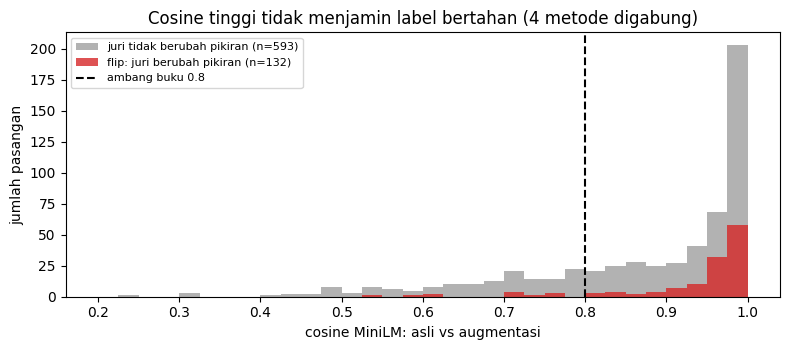

Negasi yang lolos filter DAN tidak membuat juri berubah pikiran -- kedua juri 'menyetujui':
   cos 0.960 | an unusually dry-eyed , even analytical approach to material that is not generally played for maximum moisture .
   cos 0.991 | affecting story about four sisters who are not coping , in one way or another , with life
   cos 0.987 | emerges in the movie , using a plot that could not have come from an animated-movie screenwriting textbook
Parafrase yang dibuang filter, padahal juri tidak berubah pikiran:
   cos 0.793 | as exciting as all this exoticism might sound to the typical pax viewer , the rest of us will be lulled into a coma .
               -> Although the act of being exotic may strike the pax, it will take you by surprise and put you into a coma.
   cos 0.482 | wallace is smart to vary the pitch of his movie , balancing deafening battle scenes with quieter domestic scenes of women back home receiving war department telegrams .
               -> It is a clever tactic to c

In [19]:
AUX = re.compile(r"\b(is|was|are|were|has|have|does|do|did|can|will|would|could)\b")


def negate(s):
    """Kontrol perusak label: sisipkan 'not' setelah kata kerja bantu pertama (berbasis aturan, CPU)."""
    return AUX.sub(lambda m: m.group(0) + " not", s, count=1)


def pct(num, den):
    return f"{num / den:.1%}" if den else "n/a"


random.seed(1)
AUG = {"WordNet (n=2)": [synonym_replacement_det(s, n=2) for s in S]}
tr = Translator()
AUG["back-translation fr"] = tr.translate_batch(tr.translate_batch(S, "fr", num_beams=1), "en", src="fr", num_beams=1)
del tr
release("mt:en-fr", "mt:fr-en")
AUG["paraphraser (sampling)"] = [o[0] for o in paraphrase_batch(S, 1, seed=0, num_beams=1, do_sample=True)]
release("paraphraser")

NEG_IDX = [i for i, s in enumerate(S_BIG) if AUX.search(s) and " not " not in f" {s} " and "n't" not in s]
NEG_SRC = [S_BIG[i] for i in NEG_IDX]
rows = [(k, S, v, ORACLE_S) for k, v in AUG.items()]
rows.append(("negasi (kontrol perusak)", NEG_SRC, [negate(s) for s in NEG_SRC], ORACLE_S_BIG[NEG_IDX]))

print(f"{'metode':<26}{'n':>5}{'identik':>9}{'cos rata2':>11}{'lolos 0.8':>11}{'flip juri':>11}{'P(lolos | flip)':>17}")
JUDGED = {}
for name, src, aug, pred in rows:
    cos = cos_pairs(src, aug)
    flip = oracle_label(aug) != pred
    ok = cos >= 0.8
    JUDGED[name] = (src, aug, cos, flip)
    same = np.mean([norm(a) == norm(b) for a, b in zip(aug, src)])
    print(f"{name:<26}{len(src):>5}{same:>9.1%}{cos.mean():>11.3f}{ok.mean():>11.1%}{flip.mean():>11.1%}"
          f"{pct((flip & ok).sum(), flip.sum()):>17}")

all_cos = np.concatenate([v[2] for v in JUDGED.values()])
all_flip = np.concatenate([v[3] for v in JUDGED.values()])
print(f"gabungan: lolos 0.8 = {pct((all_cos[all_flip] >= 0.8).sum(), all_flip.sum())} dari {int(all_flip.sum())} pasangan flip "
      f"vs {pct((all_cos[~all_flip] >= 0.8).sum(), (~all_flip).sum())} dari {int((~all_flip).sum())} pasangan tanpa flip")

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(0.2, 1.0, 33)
ax.hist(all_cos[~all_flip], bins=bins, alpha=0.6, color="tab:gray", label=f"juri tidak berubah pikiran (n={int((~all_flip).sum())})")
ax.hist(all_cos[all_flip], bins=bins, alpha=0.8, color="tab:red", label=f"flip: juri berubah pikiran (n={int(all_flip.sum())})")
ax.axvline(0.8, ls="--", c="k", label="ambang buku 0.8")
ax.set_xlabel("cosine MiniLM: asli vs augmentasi")
ax.set_ylabel("jumlah pasangan")
ax.set_title("Cosine tinggi tidak menjamin label bertahan (4 metode digabung)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

src, aug, cos, flip = JUDGED["negasi (kontrol perusak)"]
print("Negasi yang lolos filter DAN tidak membuat juri berubah pikiran -- kedua juri 'menyetujui':")
for i in [i for i in range(len(aug)) if cos[i] >= 0.8 and not flip[i]][:3]:
    print(f"   cos {cos[i]:.3f} | {aug[i]}")
src, aug, cos, flip = JUDGED["paraphraser (sampling)"]
print("Parafrase yang dibuang filter, padahal juri tidak berubah pikiran:")
for i in [i for i in range(len(aug)) if cos[i] < 0.8 and not flip[i]][:3]:
    print(f"   cos {cos[i]:.3f} | {src[i]}\n               -> {aug[i]}")

Baris kontrol negasi menjawab pertanyaannya dengan telak. Di run historis (pada 343 kalimat validation), negasi mendapat cosine
rata-rata **0,971** — tertinggi dari semua metode — 98,8% lolos filter, juri berubah pikiran pada 40,2%, dan **97,1% dari pasangan
yang membuat juri berubah pikiran tetap lolos filter**. Angka flip 40,2% itu batas bawah: tidak setiap sisipan *not* membalik
sentimen (negasi bisa jatuh di klausa sampingan), dan juri pun bisa melewatkan negasi. Daftar pertama di bawah histogram
memperlihatkan kasus yang paling berbahaya: kalimat yang maknanya terbalik, tetapi lolos cosine **dan** tidak membuat juri berubah
pikiran. Kedua alat otomatis menyetujuinya; hanya pembaca manusia yang bisa menolaknya.

Tiga metode sungguhan menempati wilayah yang berbeda. Back-translation paling setia (run historis: cosine 0,871, lolos 80,0%),
WordNet di tengah (0,830, lolos 64,2%), dan parafrase paling bervariasi sekaligus paling dihukum filter (lolos 33,3%) walaupun
flip-nya (15,8%) tidak jauh dari WordNet (13,3%). Daftar kedua menunjukkan parafrase yang dibuang filter padahal juri tidak
berubah pikiran — kandidat data bagus yang hilang.

Histogram menyatukan keempatnya: massa merah (flip) menumpuk di cosine 0,95–1,0, tepat di wilayah yang paling "aman" menurut filter.
Ambang 0,8 adalah ukuran kemiripan topik dan struktur, bukan ukuran makna, apalagi label. Untuk menjaga label dibutuhkan pemeriksa
label: classifier seperti juri di notebook ini (dengan kesalahannya sendiri), model NLI yang memeriksa *entailment* dua arah, atau
manusia.

### Synonym replacement dengan contextual word embeddings

Kata "bank" punya vektor berbeda di "river bank" dan "savings bank" bila diambil dari model kontekstual seperti BERT. Buku berharap
sinonimnya pun ikut kontekstual ("shore" untuk tepi sungai, "financial institution" untuk bank).

> **Listing buku: `contextual_synonym_replacement`**
>
> ```python
> inputs = tokenizer(text, return_tensors="pt")
> outputs = model(inputs)                                       # BatchEncoding dikirim sebagai argumen posisional
> word_embedding = outputs.last_hidden_state[0, word_index]     # indeks kata dipakai sebagai indeks token
> similar_words = find_similar_words(word_embedding, model, tokenizer)   # tidak didefinisikan di buku
> ```
>
> Tiga masalah. `model(inputs)` mengirim seluruh dict tokenizer sebagai `input_ids`, dan BERT gagal dengan `AttributeError` tanpa
> pesan (run historis); yang benar `model(**inputs)`. `find_similar_words` tidak didefinisikan (buku menyebutnya *undefined*).
> Yang paling licin: `word_index` menghitung kata hasil `text.split()`, sedangkan `last_hidden_state` diindeks per token BERT, yang
> diawali `[CLS]` dan memecah sebagian kata menjadi beberapa *subword*. Bug terakhir ini tidak memunculkan error sama sekali.

Sel pertama memperlihatkan pergeseran indeks itu pada contoh buku, lalu menghitungnya untuk semua kata di `S_BIG`. Pemetaan yang
benar memakai *offset* karakter yang dikembalikan tokenizer.

In [20]:
def word_first_tokens(text, tokenizer):
    """Untuk setiap kata hasil text.split(): indeks token pertamanya, lewat offset karakter tokenizer."""
    enc = tokenizer(text, return_offsets_mapping=True, truncation=True, max_length=512)
    starts, pos = [], 0
    for w in text.split():
        pos = text.index(w, pos)
        starts.append(pos)
        pos += len(w)
    owner = [None if e == s else max(i for i, st in enumerate(starts) if st <= s) for s, e in enc["offset_mapping"]]
    first = [owner.index(i) for i in range(len(starts))]
    return enc, owner, first


mlm_tok = get("mlm")[0]
text = "the river bank was flooded after the storm"
enc, owner, first = word_first_tokens(text, mlm_tok)
toks = mlm_tok.convert_ids_to_tokens(enc["input_ids"])
print(f"{'kata':<9}{'token di posisi word_index (cara buku)':<42}{'token pertama kata itu'}")
for wi, w in enumerate(text.split()):
    print(f"{w:<9}{f'posisi {wi} = {toks[wi]}':<42}{f'posisi {first[wi]} = {toks[first[wi]]}'}")

cats = collections.Counter()
for s in S_BIG:
    enc, owner, first = word_first_tokens(s, mlm_tok)
    for wi in range(len(s.split())):
        o = owner[wi]
        cats["[CLS]" if o is None else ("kata itu sendiri" if o == wi else
                                        ("kata tepat sebelumnya" if o == wi - 1 else "kata lebih jauh di belakang"))] += 1
total = sum(cats.values())
print(f"\nS_BIG, {total:,} kata: token di last_hidden_state[0, word_index] milik ...")
for k in ["kata itu sendiri", "[CLS]", "kata tepat sebelumnya", "kata lebih jauh di belakang"]:
    print(f"   {k:<28}{cats[k]:>7,} ({cats[k] / total:.1%})")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[muat]  mlm -> cuda:0 | GPU teralokasi 0.75 GiB
kata     token di posisi word_index (cara buku)    token pertama kata itu
the      posisi 0 = [CLS]                          posisi 1 = the
river    posisi 1 = the                            posisi 2 = river
bank     posisi 2 = river                          posisi 3 = bank
was      posisi 3 = bank                           posisi 4 = was
flooded  posisi 4 = was                            posisi 5 = flooded
after    posisi 5 = flooded                        posisi 6 = after
the      posisi 6 = after                          posisi 7 = the
storm    posisi 7 = the                            posisi 8 = storm

S_BIG, 16,384 kata: token di last_hidden_state[0, word_index] milik ...
   kata itu sendiri                  0 (0.0%)
   [CLS]                         1,000 (6.1%)
   kata tepat sebelumnya         7,209 (44.0%)
   kata lebih jauh di belakang   8,175 (49.9%)


Tabel atas memperlihatkan pergeserannya secara konkret: kata pertama selalu membaca `[CLS]`, `bank` membaca token milik `river`,
dan `storm` membaca token milik `the`. Porsi "kata itu sendiri" di hitungan bawahnya selalu nol, dan itu bukan kebetulan: karena
`[CLS]` menempati posisi 0, token pertama kata ke-*i* paling cepat berada di posisi *i*+1. Setiap tanda baca dan subword menambah
geser, sehingga sebagian besar posisi membaca kata yang lebih jauh di belakang. Fungsinya tetap menghasilkan kalimat bahasa
Inggris yang wajar — hanya kandidatnya untuk kata yang salah.

Dengan posisi yang benar, ada dua cara mengambil kandidat. **Desain buku**: biarkan kata aslinya terlihat dan baca kepala
*masked language model* (MLM) BERT di posisinya — itulah pelengkapan `find_similar_words` di sini. **Contextual augmentation**
(Kobayashi, 2018): ganti kata itu dengan `[MASK]`, lalu minta BERT menebak apa yang cocok di slot itu. Keduanya dibandingkan pada
contoh buku dan pada kata sentimen, lalu diukur pada kalimat `S` dengan dua kebijakan: kata dipilih acak (kebijakan buku), dan kata
yang paling menentukan label menurut juri. Kata penentu itu dicari lewat **oklusi**: hapus satu kata, lihat seberapa jauh
P(positif) juri bergeser, dan ambil kata dengan geseran terbesar.

In [21]:
def context_candidates(text, wi, model, tokenizer, masked=False, k=5):
    """Kandidat pengganti kata ke-wi dari kepala MLM di posisi token yang benar (versi kerja find_similar_words)."""
    words = text.split()
    if masked:
        inputs = tokenizer(" ".join(words[:wi] + [tokenizer.mask_token] + words[wi + 1:]), return_tensors="pt",
                           truncation=True, max_length=512)
        pos = int((inputs["input_ids"][0] == tokenizer.mask_token_id).nonzero()[0, 0])
    else:
        inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=512)
        pos = word_first_tokens(text, tokenizer)[2][wi]
    with torch.inference_mode():
        logits = check_finite(model(**inputs.to(model.device)).logits[0, pos], "logits MLM")
    ranked = tokenizer.convert_ids_to_tokens(logits.topk(50).indices.tolist())
    return [w for w in ranked if w.isalpha() and w != words[wi].lower()][:k]


def contextual_synonym_replacement(text, model, tokenizer, n=1, masked=False):
    """Listing buku setelah diperbaiki: model(**inputs), posisi token yang benar, kandidat dari kepala MLM."""
    words = text.split()
    new_words = words.copy()
    for _ in range(n):
        word_index = random.randint(0, len(words) - 1)
        similar_words = context_candidates(text, word_index, model, tokenizer, masked=masked)
        if similar_words:
            new_words[word_index] = random.choice(similar_words)
    return " ".join(new_words)


def salient_index(text):
    """Indeks kata yang paling menggeser P(positif) juri bila dihapus (oklusi)."""
    words = text.split()
    p = oracle_proba([text] + [" ".join(words[:i] + words[i + 1:]) for i in range(len(words))])
    return int(np.argmax(np.abs(p[1:] - p[0])))


def replace_at(text, wi, cands):
    words = text.split()
    if cands:
        words[wi] = random.choice(cands)
    return " ".join(words)


mlm_model = get("mlm")[1]
for text, word in [("the river bank was flooded after the storm", "bank"),
                   ("she deposited the check at the bank on monday", "bank"),
                   ("the movie was boring and far too long", "boring"),
                   ("the acting was superb but the plot was predictable", "superb")]:
    wi = text.split().index(word)
    print(f"{word!r} dalam '{text}'")
    print(f"   tanpa mask (desain buku, posisi benar): {', '.join(context_candidates(text, wi, mlm_model, mlm_tok, k=8))}")
    print(f"   dengan [MASK]                         : {', '.join(context_candidates(text, wi, mlm_model, mlm_tok, True, k=8))}")

print(f"\n{'ganti 1 kata acak (' + str(len(S)) + ' kalimat S)':<44}{'cos ke asli':>12}{'flip juri':>11}")
for name, fn in [("WordNet, filter isalnum (buku)", lambda s: synonym_replacement_det(s, n=1)),
                 ("kontekstual tanpa mask", lambda s: contextual_synonym_replacement(s, mlm_model, mlm_tok)),
                 ("kontekstual dengan [MASK]", lambda s: contextual_synonym_replacement(s, mlm_model, mlm_tok, masked=True))]:
    random.seed(2)
    aug = [fn(s) for s in S]
    print(f"{name:<44}{cos_pairs(S, aug).mean():>12.3f}{np.mean(oracle_label(aug) != ORACLE_S):>11.1%}")

SAL = [salient_index(s) for s in S]
print(f"\nkata paling menentukan menurut oklusi juri (8 pertama): {[s.split()[wi] for s, wi in zip(S[:8], SAL[:8])]}")
print(f"{'ganti kata itu (' + str(len(S)) + ' kalimat S)':<44}{'berubah':>9}{'cos ke asli':>12}{'flip juri':>11}")
for name, cand_fn in [("WordNet", lambda s, wi: sorted(get_synonyms(s.split()[wi]))),
                      ("kontekstual tanpa mask", lambda s, wi: context_candidates(s, wi, mlm_model, mlm_tok)),
                      ("kontekstual dengan [MASK]", lambda s, wi: context_candidates(s, wi, mlm_model, mlm_tok, True))]:
    random.seed(4)
    aug = [replace_at(s, wi, cand_fn(s, wi)) for s, wi in zip(S, SAL)]
    print(f"{name:<44}{np.mean([a != s for a, s in zip(aug, S)]):>9.1%}{cos_pairs(S, aug).mean():>12.3f}"
          f"{np.mean(oracle_label(aug) != ORACLE_S):>11.1%}")
del mlm_model
release("mlm")

'bank' dalam 'the river bank was flooded after the storm'
   tanpa mask (desain buku, posisi benar): banks, bed, side, banking, bottom, bridge, mouth, channel
   dengan [MASK]                         : itself, thames, avon, seine, dee, severn, clyde, tyne
'bank' dalam 'she deposited the check at the bank on monday'
   tanpa mask (desain buku, posisi benar): banks, account, church, building, firm, wall, treasury, reserve
   dengan [MASK]                         : office, atm, door, desk, counter, hotel, teller, register
'boring' dalam 'the movie was boring and far too long'
   tanpa mask (desain buku, posisi benar): dull, long, short, bored, hours, late, spent, paced
   dengan [MASK]                         : long, short, good, slow, beautiful, bad, old, fast
'superb' dalam 'the acting was superb but the plot was predictable'
   tanpa mask (desain buku, posisi benar): good, wonderful, excellent, brilliant, marvelous, well, outstanding, great
   dengan [MASK]                         : go

Contoh "bank" milik buku diuji langsung. Tanpa mask, kandidat memang bergeser mengikuti konteks — di run historis `bed, side,
bottom` untuk tepi sungai dan `account, firm, treasury` untuk bank tempat menyetor cek — walau bukan "shore" dan "financial
institution" seperti janji buku, dan kandidat teratas di kedua konteks adalah `banks`, bentuk jamak kata yang sama. Dengan `[MASK]`,
model tidak lagi tahu kata aslinya dan hanya menebak apa yang cocok di slot: nama-nama sungai untuk "the river ___". Pada kata
sentimen bedanya menentukan (run historis): tanpa mask, `superb` mendapat `good, wonderful, excellent`; dengan mask, daftarnya
memuat `poor`, `bad`, dan `terrible`. Antonim cocok di slot yang sama persis — masalah yang dikenali Kobayashi sejak awal,
sehingga ia menambahkan model bahasa yang dikondisikan pada label.

Dua tabel di bawahnya menjelaskan kenapa hal itu penting. Dengan kata acak (kebijakan buku), metode kontekstual terlihat lebih setia
dan jarang membalik label, karena kata acak kebanyakan kata netral. Daftar kata hasil oklusi hampir selalu kata sentimen, dan di
posisi itu semua metode jauh lebih berbahaya: di run historis WordNet membalik 20,0%, kontekstual tanpa mask 25,0%, dan dengan
mask 30,8% — hampir satu dari tiga — sementara cosine ketiganya tetap sekitar 0,94–0,95, jauh di atas ambang 0,8. Konteks memilih
kata yang lebih *wajar*, tetapi kewajaran bukan kesetiaan makna.

## Menyeimbangkan augmentasi dan kualitas

Buku menyarankan membatasi porsi data augmentasi, dimulai dari rasio 1:1 antara data asli dan data augmentasi, lalu disesuaikan
dengan performa model. Rasio itu diuji di akhir bab. Sebelumnya, saringan kualitasnya.

### Quality filtering

Augmentasi lolos bila mirip secara semantik (cosine ≥ 0,8) **dan** wajar menurut model bahasa. Kewajaran diukur dengan
**perplexity**: exp dari rata-rata *loss* per token, atau kira-kira "dari berapa token model ragu memilih pada setiap langkah".
Makin kecil, makin wajar teks itu bagi model. Buku memakai ambang perplexity ≤ 100.

> **Listing buku: `quality_filter`**
>
> ```python
> semantic_similarity(original_text, aug_text, similarity_model) >= similarity_threshold and
> calculate_perplexity(aug_text, perplexity_model) <= perplexity_threshold
> ```
>
> `similarity_model`, `perplexity_model`, dan `calculate_perplexity` tidak didefinisikan di bab ini, dan buku tidak menyebutnya;
> pemanggilan pertama berhenti dengan `NameError: name 'similarity_model' is not defined` (run historis). Pelengkapan di bawah:
> `similarity_model` adalah juri makna, `perplexity_model` adalah GPT-2 124M di GPU, dan `calculate_perplexity` menghitung exp
> dari loss rata-rata. Badan `quality_filter` tidak diubah.

In [22]:
similarity_model = get("embedder")[1]   # pelengkapan: juri makna MiniLM
perplexity_model = get("lm")[1]         # pelengkapan: GPT-2 124M; dilepas setelah bagian perplexity
lm_tok = get("lm")[0]
lm_tok.pad_token = lm_tok.eos_token


def calculate_perplexity(text, model):   # pelengkapan: exp(rata-rata loss per token yang diprediksi)
    enc = lm_tok(text, return_tensors="pt").to(model.device)
    if enc["input_ids"].shape[1] < 2:
        raise ValueError(f"perplexity butuh >= 2 token: {text!r}")
    with torch.inference_mode():
        loss = check_finite(model(**enc, labels=enc["input_ids"]).loss, "loss GPT-2")
    return math.exp(loss.item())


def quality_filter(
    augmented_texts, original_text,
    similarity_threshold=0.8, perplexity_threshold=100
):   # listing buku, tidak diubah
    filtered_texts = []
    for aug_text in augmented_texts:
        if (
            semantic_similarity(
                original_text, aug_text, similarity_model
            ) >= similarity_threshold and
            calculate_perplexity(
                aug_text, perplexity_model
            ) <= perplexity_threshold
        ):
            filtered_texts.append(aug_text)
    return filtered_texts


print(f"kalimat asli           | ppl {calculate_perplexity(ORIG, perplexity_model):7.1f} | {ORIG}")
for c in CANDS:
    print(f"cos {semantic_similarity(ORIG, c, similarity_model):.3f} | ppl {calculate_perplexity(c, perplexity_model):7.1f} | {c}")
print("quality_filter mempertahankan:", quality_filter(CANDS, ORIG))

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

[muat]  lm -> cuda:0 | GPU teralokasi 0.81 GiB
kalimat asli           | ppl    96.5 | The movie was boring and far too long.
cos 0.984 | ppl   114.4 | The film was boring and far too long.
cos 0.699 | ppl   193.8 | The movie was uninteresting and stretched beyond its timeframe.
cos 0.636 | ppl   191.2 | The film was uninteresting and stretched beyond its timeframe.
cos 0.584 | ppl  2095.0 | The movie was tire and alir too long.
cos 0.974 | ppl   113.5 | The movie was not boring and far too long.
cos 0.868 | ppl   115.2 | The movie was exciting and far too long.
cos 0.953 | ppl   108.3 | The movie was boring and far too short.
quality_filter mempertahankan: []


Di run historis, filter yang sudah lengkap ini menolak **ketujuh** kandidat. Kalimat aslinya sendiri hanya lolos tipis (perplexity
96,5), dan back-translation yang hanya mengganti `movie` menjadi `film` sudah gagal di 114,4. Ambang 100 jatuh tepat di wilayah
perplexity kalimat pendek yang sepenuhnya normal, sehingga keputusannya ditentukan hal sepele seperti pilihan satu kata benda.
Negasi dan antonim memang layak ditolak, tetapi alasannya kebetulan: perplexity mereka setara dengan back-translation yang setia.

Sel berikut menguji ambang yang sama pada skala, termasuk pada kalimat asli SST-2 sendiri. `ppl_batch` menghitung perplexity banyak
teks sekaligus di GPU dengan *attention mask* (token padding tidak ikut dihitung); asersi di awal memastikan hasilnya sama dengan
`calculate_perplexity`. Di bagian akhir, ambang absolut dibandingkan dengan kriteria **relatif**: varian lolos bila perplexity-nya
tidak lebih dari 1,5 kali perplexity kalimat sumbernya sendiri.

In [23]:
def ppl_batch(texts, bs=None):
    """Perplexity per teks dalam batch (padding kanan + attention mask) di DEVICE."""
    texts = list(texts)
    bs = bs or CFG["bs"]
    out = []
    with torch.inference_mode():
        for b in range(0, len(texts), bs):
            enc = lm_tok(texts[b:b + bs], return_tensors="pt", padding=True).to(DEVICE)
            logits = perplexity_model(**enc).logits[:, :-1].float()
            tgt = enc["input_ids"][:, 1:]
            m = enc["attention_mask"][:, 1:].float()
            if (m.sum(1) == 0).any():
                raise ValueError("ada teks dengan kurang dari 2 token")
            nll = torch.nn.functional.cross_entropy(logits.transpose(1, 2), tgt, reduction="none")
            out += check_finite(((nll * m).sum(1) / m.sum(1)).exp(), "perplexity batch").cpu().tolist()
    return np.array(out)


rel = np.abs(ppl_batch(CANDS) / np.array([calculate_perplexity(c, perplexity_model) for c in CANDS]) - 1)
assert rel.max() < 1e-3, f"ppl_batch menyimpang dari calculate_perplexity: {rel.max():.1e}"
print(f"ppl_batch vs calculate_perplexity: selisih relatif maksimum {rel.max():.1e}")

P_S = ppl_batch(S)
P_DET = ppl_batch([detok(s) for s in S])
print(f"\n{'teks (' + str(len(S)) + ' kalimat S)':<34}{'median ppl':>11}{'lolos <= 100':>14}")
print(f"{'asli, gaya token SST-2':<34}{np.median(P_S):>11.0f}{(P_S <= 100).mean():>14.1%}")
print(f"{'asli, didetokenisasi':<34}{np.median(P_DET):>11.0f}{(P_DET <= 100).mean():>14.1%}")
PPL_AUG = {name: ppl_batch(aug) for name, aug in AUG.items()}
for name, p in PPL_AUG.items():
    print(f"{name:<34}{np.median(p):>11.0f}{(p <= 100).mean():>14.1%}")
print("\nkriteria relatif: ppl(varian) <= 1,5 x ppl(kalimat sumbernya)")
for name, p in PPL_AUG.items():
    print(f"   {name:<26} lolos {(p <= 1.5 * P_S).mean():.1%}")

ppl_batch vs calculate_perplexity: selisih relatif maksimum 2.3e-05

teks (120 kalimat S)               median ppl  lolos <= 100
asli, gaya token SST-2                    166         25.8%
asli, didetokenisasi                      115         42.5%
WordNet (n=2)                             399          3.3%
back-translation fr                       167         30.0%
paraphraser (sampling)                    102         49.2%

kriteria relatif: ppl(varian) <= 1,5 x ppl(kalimat sumbernya)
   WordNet (n=2)              lolos 20.8%
   back-translation fr        lolos 77.5%
   paraphraser (sampling)     lolos 87.5%


Baris kedua tabel adalah temuan pentingnya. Di run historis, hanya **20,0% kalimat asli** SST-2 yang lolos ambang 100 (median
perplexity 224). Filter kualitas yang menolak empat dari lima kalimat buatan manusia tidak sedang mengukur kualitas. Sebagian
besar penyebabnya format: SST-2 ditulis huruf kecil dengan tanda baca dipisah spasi (`it 's a charming ...`), gaya yang jarang
dilihat GPT-2. Detokenisasi sederhana menurunkan median ke 130 dan menaikkan yang lolos ke 43,3% — kata yang sama, format berbeda.

Efek format terbawa ke perbandingan antar-metode: parafrase dan back-translation diuntungkan karena outputnya berhuruf kapital dan
bertanda baca rapi, sedangkan WordNet ditolak hampir semuanya karena kalimatnya memang rusak. Kriteria relatif lebih jujur karena
membandingkan setiap varian dengan sumbernya sendiri: di run historis 90,0% parafrase dan 83,3% back-translation lolos, sedangkan
WordNet tertahan di 30,8%. Filter relatif menolak teks yang menjadi *lebih rusak dari sumbernya*, bukan teks yang kebetulan bergaya
beda dari data pretraining GPT-2. Untuk label, tetap dibutuhkan pemeriksa label.

### Human-in-the-loop validation

Untuk aplikasi kritis, manusia menjadi saringan terakhir.

> **Listing buku: `human_validation`**
>
> ```python
> if input(f"Is this text valid? (y/n)\n{text}\n").lower() == 'y':
>     validated_texts.append(text)
> ```
>
> Fungsi ini benar secara sintaks, tetapi `input()` membuat **Run all** berhenti menunggu ketikan. Aturannya juga sangat ketat:
> hanya `y`/`Y` yang diterima; `yes` atau ` y` (spasi di depan) dianggap tolak, dan sampel yang ditolak hilang tanpa catatan.
> Validator juga hanya melihat teks augmentasi, tanpa teks aslinya.

Versi kerja di bawah menampilkan teks asli di samping augmentasi, menerima `y/yes/n/no`, mengulang pertanyaan untuk jawaban lain,
dan mencatat setiap keputusan beserta validatornya. Demo memakai **validator skrip** (bukan manusia) dengan jawaban yang meniru
variasi ketikan operator; untuk menilai sendiri di Colab, panggil dengan `ask=input`.

In [24]:
ANSWERS = ["y", "Y", "yes", " y", "n"]
print("aturan buku `.lower() == 'y'`:", {a: a.lower() == "y" for a in ANSWERS})


def human_validation(pairs, ask, reviewer):
    """Versi kerja: tampilkan asli + augmentasi, terima y/yes/n/no, ulangi jawaban lain, catat semua keputusan."""
    decisions = []
    for original, augmented in pairs:
        while True:
            answer = ask(f"ASLI : {original}\nAUGM : {augmented}\nLabel masih sama dan teks layak? (y/n) ").strip().lower()
            if answer in {"y", "yes", "n", "no"}:
                break
            print(f"   jawaban {answer!r} tidak dikenali -> pertanyaan diulang")
        decisions.append({"original": original, "augmented": augmented, "keep": answer in {"y", "yes"},
                          "answer": answer, "reviewer": reviewer})
    return decisions


def scripted_ask(answers):
    """Validator skrip untuk demo Run all, bukan penilaian manusia."""
    it = iter(answers)

    def ask(prompt):
        answer = next(it)
        print(prompt + answer)
        return answer
    return ask


DECISIONS = human_validation([(ORIG, c) for c in CANDS[:5]], ask=scripted_ask(["y", "Y", "yes", " y", "ok", "n"]),
                             reviewer="skrip-demo")
print(f"\ndisimpan {sum(d['keep'] for d in DECISIONS)} dari {len(DECISIONS)}; "
      f"{len(DECISIONS)} keputusan tercatat lengkap dengan validatornya")

aturan buku `.lower() == 'y'`: {'y': True, 'Y': True, 'yes': False, ' y': False, 'n': False}
ASLI : The movie was boring and far too long.
AUGM : The film was boring and far too long.
Label masih sama dan teks layak? (y/n) y
ASLI : The movie was boring and far too long.
AUGM : The movie was uninteresting and stretched beyond its timeframe.
Label masih sama dan teks layak? (y/n) Y
ASLI : The movie was boring and far too long.
AUGM : The film was uninteresting and stretched beyond its timeframe.
Label masih sama dan teks layak? (y/n) yes
ASLI : The movie was boring and far too long.
AUGM : The movie was tire and alir too long.
Label masih sama dan teks layak? (y/n)  y
ASLI : The movie was boring and far too long.
AUGM : The movie was not boring and far too long.
Label masih sama dan teks layak? (y/n) ok
   jawaban 'ok' tidak dikenali -> pertanyaan diulang
ASLI : The movie was boring and far too long.
AUGM : The movie was not boring and far too long.
Label masih sama dan teks layak? (y/n)

Baris pertama memperlihatkan aturan buku: dari lima jawaban yang wajar diketik operator, hanya `y` dan `Y` yang diterima. Versi
kerja menerima `yes` dan ` y`, menolak `ok` sampai ada jawaban yang dikenali, dan mengembalikan **semua** keputusan, bukan hanya
yang diterima. Dengan catatan seperti itu, kesepakatan antar-validator bisa diukur, dan "ditolak karena buruk" bisa dibedakan dari
"ditolak karena salah ketik". Menampilkan teks asli juga bukan kosmetik: kalimat kelima, negasi yang membalik label, terbaca sebagai
kalimat yang sempurna bila berdiri sendiri. (Jawaban skrip menerima kalimat WordNet yang rusak — itu ketikan demo, bukan penilaian.)

## Mengevaluasi dampak augmentasi

### Perplexity

Buku menyarankan mengukur perplexity model pada test set sebelum dan sesudah augmentasi.

> **Listing buku: `evaluate_perplexity`**
>
> ```python
> outputs = model(inputs, labels=inputs["input_ids"])
> total_loss += outputs.loss.item() * inputs["input_ids"].size(1)
> total_tokens += inputs["input_ids"].size(1)
> ```
>
> Tiga masalah, semuanya terverifikasi di run historis (CPU). (1) Bug `model(inputs)` yang sama dengan listing kontekstual,
> kali ini pada GPT-2: `AttributeError` tanpa pesan; yang benar `model(**inputs, labels=...)`. (2) Setelah baris itu
> diperbaiki, loss GPT-2 — rata-rata atas n−1 prediksi, karena token pertama tidak pernah diprediksi — ditimbang dengan n:
> 164,52 melawan 163,23 dengan bobot yang benar pada 200 kalimat validation (bias sekitar 0,8%). (3) Teks sepanjang satu token
> tidak punya prediksi sama sekali, sehingga loss-nya NaN dan meracuni seluruh jumlah: 20 kalimat validation memberi 187,8,
> tetapi 20 kalimat yang sama ditambah satu baris `'men'` memberi `nan` — tanpa error, tanpa peringatan.

Sel berikut hanya memuat versi kerja: bobot = jumlah token yang benar-benar diprediksi (n−1), teks kurang dari dua token
dilewati dan dihitung, dan loss NaN/inf menghentikan evaluasi. Versi itu dijalankan pada sampel validation, lalu pada kasus yang
meracuni listing: 20 kalimat ditambah satu baris satu-token dari SST-2 train.

In [25]:
def evaluate_perplexity_robust(model, tokenizer, test_data):
    """Bobot n-1 (token yang benar-benar diprediksi); teks < 2 token dilewati dan dihitung; NaN/inf menghentikan evaluasi."""
    model.eval()
    total_nll, total_pred, skipped = 0.0, 0, 0
    with torch.inference_mode():
        for text in test_data:
            inputs = tokenizer(text, return_tensors="pt").to(model.device)
            n_pred = inputs["input_ids"].size(1) - 1
            if n_pred < 1:
                skipped += 1
                continue
            loss = check_finite(model(**inputs, labels=inputs["input_ids"]).loss, f"loss untuk {text!r}")
            total_nll += loss.item() * n_pred
            total_pred += n_pred
    return math.exp(total_nll / total_pred), skipped


TEST = EVAL_X[:CFG["n_ppl"]]
ppl_test, skipped_test = evaluate_perplexity_robust(perplexity_model, lm_tok, TEST)
print(f"{len(TEST)} kalimat validation: perplexity GPT-2 {ppl_test:.2f} (bobot n-1) | teks dilewati {skipped_test}")

lens = [len(x) for x in lm_tok([s for s, _ in TRAIN_ROWS])["input_ids"]]
ONE = [s for (s, _), n in zip(TRAIN_ROWS, lens) if n == 1]
assert ONE, "diharapkan ada baris satu-token di SST-2 train"
print(f"baris unik SST-2 train yang hanya 1 token GPT-2: {len(ONE):,} dari {len(TRAIN_ROWS):,}, contoh {ONE[:5]}")
ppl_20, skipped_20 = evaluate_perplexity_robust(perplexity_model, lm_tok, EVAL_X[:20])
ppl_mixed, skipped_mixed = evaluate_perplexity_robust(perplexity_model, lm_tok, EVAL_X[:20] + ONE[:1])
assert skipped_20 == 0 and skipped_mixed == 1, (skipped_20, skipped_mixed)
assert math.isfinite(ppl_mixed) and math.isclose(ppl_mixed, ppl_20, rel_tol=1e-9)
print(f"20 kalimat: {ppl_20:.2f} | 20 kalimat + {ONE[0]!r}: {ppl_mixed:.2f}, {skipped_mixed} teks dilewati, "
      f"finite: {math.isfinite(ppl_mixed)}")
del perplexity_model
release("lm")

200 kalimat validation: perplexity GPT-2 163.23 (bobot n-1) | teks dilewati 0
baris unik SST-2 train yang hanya 1 token GPT-2: 432 dari 66,973, contoh ['men', 'free', 'grand', 'thank', 'bite']
20 kalimat: 185.67 | 20 kalimat + 'men': 185.67, 1 teks dilewati, finite: True
[lepas] lm | masih dimuat: ['embedder', 'oracle'] | GPU teralokasi 0.34 GiB


Angka pertama adalah perplexity GPT-2 pada kalimat validation dengan bobot yang benar (run historis notebook asal pada 200
kalimat: 163,23). Baris berikutnya menjelaskan kenapa versi kerja perlu melewati teks pendek: SST-2 memuat frasa sependek satu
kata (432 baris unik seperti `men`, `free`, `thank`). Baris terakhir memperlihatkan perlakuannya: baris satu-token dilewati dan
dihitung, hasilnya tetap finite, dan nilainya sama dengan 20 kalimat tanpa baris itu — asersi di sel menjaga ketiganya.
Bandingkan dengan kotak listing di atas, tempat satu baris yang sama mengubah seluruh hasil menjadi `nan`.

Satu catatan konsep: perplexity mengukur seberapa baik sebuah *model* memprediksi teks. "Sebelum dan sesudah augmentasi" berarti
dua model — satu dilatih tanpa, satu dengan data augmentasi — dievaluasi pada test set yang sama. Untuk data klasifikasi seperti di
bab ini, metrik tugas di bawah lebih relevan.

### Metrik spesifik tugas

> **Listing buku: `evaluate_classification`**
>
> ```python
> outputs = model(inputs)
> predictions.append(torch.argmax(outputs.logits).item())
> ```
>
> Bug `model(inputs)` lagi, kali ini dengan exception berbeda karena arsitekturnya berbeda: DistilBERT meneruskan dict ke lapisan
> embedding dan gagal dengan `TypeError: embedding(): argument 'indices' ... must be Tensor, not BatchEncoding` (run historis).
> Ada juga bug yang menunggu: `torch.argmax(outputs.logits)` tanpa `dim` mengambil argmax dari tensor yang diratakan, sehingga hanya
> benar untuk batch berisi satu kalimat.

Versi kerja memakai `model(**inputs)`, batch, dan `argmax(dim=-1)`, lalu dijalankan dengan juri label pada 872 kalimat validation.
Baris pertama sel memperlihatkan bug `argmax` pada tensor kecil buatan.

In [26]:
from sklearn.metrics import accuracy_score, f1_score   # pelengkapan: listing buku tidak menulis import ini

demo_logits = torch.tensor([[0.1, 0.9], [0.8, 0.2]])   # tensor buatan: 2 kalimat x 2 kelas
print(f"tensor buatan: argmax tanpa dim -> {torch.argmax(demo_logits).item()} (indeks datar) | "
      f"argmax(dim=-1) -> {demo_logits.argmax(dim=-1).tolist()}")


def evaluate_classification(
    model, tokenizer, test_data, test_labels, bs=64
):   # listing buku diperbaiki: model(**inputs), batch, argmax(dim=-1)
    model.eval()
    predictions = []
    with torch.inference_mode():
        for b in range(0, len(test_data), bs):
            inputs = tokenizer(
                list(test_data[b:b + bs]), return_tensors="pt",
                padding=True, truncation=True, max_length=128
            ).to(model.device)
            logits = check_finite(model(**inputs).logits, "logits klasifikasi")
            predictions += logits.argmax(dim=-1).cpu().tolist()
    accuracy = accuracy_score(test_labels, predictions)
    f1 = f1_score(test_labels, predictions, average='weighted')
    return accuracy, f1


acc, f1 = evaluate_classification(get("oracle")[1], get("oracle")[0], EVAL_X, EVAL_Y)
print(f"juri label di SST-2 validation: accuracy {acc:.4f} | weighted F1 {f1:.4f} | n={len(EVAL_X)}")
assert abs(acc - np.mean(ORACLE_EVAL == EVAL_Y)) < 0.005, "seharusnya sama dengan akurasi oracle_label di bagian persiapan"

tensor buatan: argmax tanpa dim -> 1 (indeks datar) | argmax(dim=-1) -> [1, 0]
juri label di SST-2 validation: accuracy 0.9106 | weighted F1 0.9105 | n=872


Akurasi dan weighted F1 hampir sama (run historis: 0,9106 dan 0,9105), dan asersi memastikan akurasinya cocok dengan
`oracle_label` di bagian persiapan. Kedekatan F1 dan akurasi wajar karena kelas SST-2 seimbang (sekitar 51% positif); keunggulan
F1 yang buku jelaskan baru terlihat di data yang timpang. Contoh tensor buatan di baris pertama menunjukkan kenapa `dim=-1` wajib
begitu fungsi ini di-batch: argmax tanpa `dim` mengembalikan satu indeks datar, bukan satu prediksi per kalimat.

### Metrik keragaman

Buku mengukur keragaman dataset dengan dua proksi: ukuran vocabulary (jumlah kata unik) dan jumlah *trigram* karakter unik
(potongan tiga huruf berurutan). Listing ini berjalan tanpa perbaikan. Yang diuji adalah **apa** yang sebenarnya diukurnya:
kalimat `S` dibandingkan dengan `S` ditambah jumlah teks yang sama dari berbagai sumber — duplikat persis, tiga metode augmentasi,
kalimat dengan 10% huruf diganti acak (*noise* murni), dan kalimat training asli lain sebagai pembanding data baru sungguhan. Kolom
terakhir menghitung ulang vocabulary setelah huruf kecil dan tanda baca dibuang. CPU.

In [27]:
def calculate_diversity_metrics(texts):   # listing buku, tidak diubah
    all_words = [word for text in texts for word in text.split()]
    vocab_size = len(set(all_words))
    all_trigrams = [text[i:i+3] for text in texts
                    for i in range(len(text)-2)]
    unique_trigrams = len(set(all_trigrams))
    return {
        "vocabulary_size": vocab_size,
        "unique_trigrams": unique_trigrams
    }


def typo(t, rate, rng):
    return "".join(rng.choice(string.ascii_lowercase) if c.isalpha() and rng.random() < rate else c for c in t)


def lex(t):
    return re.sub(r"[^a-z0-9 ]", " ", t.lower())


rng = random.Random(0)
n = len(S)
SETS = {f"asli saja ({n} teks)": S,
        "asli + duplikat persis": S + S,
        "asli + WordNet n=2": S + AUG["WordNet (n=2)"],
        "asli + back-translation fr": S + AUG["back-translation fr"],
        "asli + paraphraser": S + AUG["paraphraser (sampling)"],
        "asli + typo acak 10% huruf": S + [typo(s, 0.10, rng) for s in S],
        f"asli + {n} kalimat asli lain": S + S_BIG[n:2 * n]}
print(f"{'himpunan':<34}{'vocab':>7}{'trigram':>9}{'vocab ternormalisasi':>22}")
for name, texts in SETS.items():
    m = calculate_diversity_metrics(texts)
    v_lex = calculate_diversity_metrics([lex(t) for t in texts])["vocabulary_size"]
    print(f"{name:<34}{m['vocabulary_size']:>7}{m['unique_trigrams']:>9}{v_lex:>22}")

himpunan                            vocab  trigram  vocab ternormalisasi
asli saja (120 teks)                  919     2412                   919
asli + duplikat persis                919     2412                   919
asli + WordNet n=2                   1122     2677                  1122
asli + back-translation fr           1276     2835                  1113
asli + paraphraser                   1625     3308                  1436
asli + typo acak 10% huruf           1556     3751                  1556
asli + 120 kalimat asli lain         1492     3129                  1494


Duplikat persis tidak menambah apa pun — satu-satunya baris yang perilakunya sesuai harapan. Typo acak memberi angka **lebih
tinggi** daripada kalimat asli baru di kedua metrik (validasi lokal revisi ini pada 120 kalimat `S`: 1.556 kata dan 3.751 trigram
melawan 1.492 dan 3.129; run historis memberi pola yang sama), karena setiap typo adalah "kata baru" dan beberapa "trigram baru".
Pada sampel yang sangat kecil urutannya bisa berubah. Buku memang menyebut keragaman tinggi bisa berarti noise,
tetapi metriknya sendiri tidak punya cara membedakan keduanya.

Kolom ternormalisasi membongkar kenaikan semu lainnya: sebagian "kosakata baru" dari back-translation hanyalah `Film` vs `film` dan
`film.` vs `film` — format, bukan kosakata, karena output Marian berhuruf kapital dan bertanda baca menempel. Semua himpunan di
tabel sengaja berukuran sama, karena metrik ini juga naik hanya karena teksnya lebih banyak. Untuk perbandingan yang jujur: ukur pada
ukuran yang sama, normalisasi teks dulu, dan pasangkan dengan metrik kualitas supaya noise tidak menang.

### Kebocoran: kenapa split harus didahulukan

Sebelum menguji apakah augmentasi menolong, satu jebakan yang membuat augmentasi *terlihat* menolong. Bayangkan alurnya terbalik:
augmentasi seluruh dataset dulu, baru dibagi acak menjadi train dan test. Kalimat asli bisa jatuh di train sementara variannya —
yang hanya berbeda satu-dua kata — jatuh di test. Model lalu "menjawab" test dengan mengingat saudara kembarnya.

Sel berikut mengukur efek itu dengan classifier sederhana di CPU: TF-IDF (bobot kata dan pasangan kata) ditambah regresi logistik.
Ada 600 kalimat training lain (di luar `POOL` dan `S_BIG`), masing-masing dengan 3 varian WordNet. Dua alur dibandingkan dengan model
dan jumlah baris training yang sama. Alur **salah** membagi acak per baris setelah augmentasi. Alur **benar** membagi per grup
(kalimat asli beserta semua variannya), lalu menguji hanya pada kalimat asli dari grup yang tidak pernah dilihat. Keduanya juga
diuji pada 872 kalimat validation sebagai patokan luar.

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression


def fit_tfidf(texts, y):
    vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
    clf = LogisticRegression(C=1.0, max_iter=2000).fit(vec.fit_transform(texts), y)
    return lambda xs: clf.predict(vec.transform(xs))


def assert_split_clean(train_records, test_records):
    """Grup train dan test terpisah, test hanya berisi kalimat asli, dan tidak ada teks test yang muncul di train."""
    shared = {r[0] for r in train_records} & {r[0] for r in test_records}
    assert not shared, f"{len(shared)} grup muncul di train dan test"
    assert all(r[3] == "asli" for r in test_records), "test tidak boleh berisi varian augmentasi"
    assert not {norm(r[1]) for r in train_records} & {norm(r[1]) for r in test_records}, "teks test muncul di train"


used = pool_ids | {g for g, _, _ in S_BIG_ROWS}
L_ROWS = random.Random(2).sample([r for r in SOURCE if r[0] not in used], CFG["n_leak"])
random.seed(5)
RECORDS = [(g, s, l, "asli") for g, s, l in L_ROWS]
for k in range(3):
    RECORDS += [(g, synonym_replacement_det(s, n=2), l, f"wordnet{k}") for g, s, l in L_ROWS]

LEAK = collections.defaultdict(list)
for seed in range(3):
    idx = list(range(len(RECORDS)))
    random.Random(seed).shuffle(idx)
    train_rec = [RECORDS[i] for i in idx[:len(idx) // 2]]
    test_rec = [RECORDS[i] for i in idx[len(idx) // 2:]]
    seen = {r[0] for r in train_rec}
    predict = fit_tfidf([r[1] for r in train_rec], [r[2] for r in train_rec])
    LEAK["salah: augmentasi dulu, acak per baris"].append(
        (np.mean(predict([r[1] for r in test_rec]) == [r[2] for r in test_rec]),
         np.mean(predict(EVAL_X) == EVAL_Y), np.mean([r[0] in seen for r in test_rec]), len(train_rec)))

    groups = sorted({r[0] for r in RECORDS})
    random.Random(seed).shuffle(groups)
    test_groups = set(groups[:len(groups) // 2])
    train_rec = [r for r in RECORDS if r[0] not in test_groups]
    test_rec = [r for r in RECORDS if r[0] in test_groups and r[3] == "asli"]
    assert_split_clean(train_rec, test_rec)
    predict = fit_tfidf([r[1] for r in train_rec], [r[2] for r in train_rec])
    LEAK["benar: split per grup dulu"].append(
        (np.mean(predict([r[1] for r in test_rec]) == [r[2] for r in test_rec]),
         np.mean(predict(EVAL_X) == EVAL_Y), 0.0, len(train_rec)))

print(f"{len(L_ROWS)} kalimat asli x (1 + 3 varian WordNet) = {len(RECORDS)} baris | 3 seed pembagian")
print(f"{'alur':<40}{'baris train':>12}{'akurasi test internal':>23}{'akurasi validation':>20}{'test punya saudara di train':>29}")
for name, vals in LEAK.items():
    v = np.array(vals)
    print(f"{name:<40}{v[:, 3].mean():>12.0f}{v[:, 0].mean():>23.3f}{v[:, 1].mean():>20.3f}{v[:, 2].mean():>29.1%}")

600 kalimat asli x (1 + 3 varian WordNet) = 2400 baris | 3 seed pembagian
alur                                     baris train  akurasi test internal  akurasi validation  test punya saudara di train
salah: augmentasi dulu, acak per baris          1200                  0.925               0.673                        87.0%
benar: split per grup dulu                      1200                  0.630               0.639                         0.0%


Bacalah tabel dari kanan. Pada alur salah, sebagian besar baris test punya saudara — kalimat asli atau varian lain dari grup yang
sama — di train (validasi lokal revisi ini: 87,0%); pada alur benar nol, dan `assert_split_clean` menjaganya. Sekarang bandingkan
dua kolom akurasi di setiap baris. "Akurasi test internal" adalah angka yang dilaporkan sebuah alur kepada dirinya sendiri; akurasi
validation adalah patokan luar yang sama untuk keduanya. Di validasi lokal, alur benar melaporkan 0,630 dan benar-benar mencapai
0,639 di validation: perkiraannya jujur. Alur salah melaporkan 0,925, padahal di validation hanya 0,673 — lebih dari 25 poin
terlalu optimistis. Model tidak menjadi jauh lebih pintar; test-nya yang menjadi jauh lebih mudah, karena berisi saudara kembar
data training. (Akurasi validation alur salah sedikit lebih tinggi karena, dengan jumlah baris yang sama, pembagian per baris
memberi train lebih banyak kalimat asli yang berbeda — bukan karena kebocoran menolong.) Bagian ini murni CPU, jadi run Colab
seharusnya memberi angka yang sama kecuali versi pustakanya berbeda.

Aturan praktisnya: bagi data menurut kalimat asli sebelum membuat varian, biarkan setiap varian mewarisi ID grup kalimat asalnya,
dan uji hanya pada kalimat asli. Eksperimen berikutnya mengikuti aturan itu.

### Di balik layar: apakah augmentasi 1:1 menolong?

Pertanyaan yang ditunda sejak awal: apakah model yang dilatih dengan data augmentasi menjadi lebih baik? Rezim yang paling
menguntungkan augmentasi dipilih — data sedikit. `POOL` berisi 150 kalimat positif dan 150 negatif dari SST-2 train (minimal 10
kata). Varian WordNet (`n=2`, CPU) dan back-translation Prancis (greedy, GPU) dibuat sekali untuk seluruh pool; setiap varian
mewarisi grup dan label kalimat asalnya. Evaluasinya selalu 872 kalimat validation yang tidak pernah di-augmentasi.

Untuk setiap seed (5 seed), diambil 32 atau 128 kalimat asli yang seimbang, lalu regresi logistik dilatih di atas dua representasi:
TF-IDF (CPU) dan embedding MiniLM (dihitung di GPU, regresinya di CPU). Lima kondisi memakai kalimat asli yang sama per seed:

- tanpa augmentasi (n baris);
- + WordNet 1:1 dan + back-translation 1:1 (2n baris; rasio yang buku sarankan);
- + keduanya 1:2 (3n baris);
- **data asli 2× lipat** (2n baris kalimat asli baru) — pembanding yang jumlah barisnya sama dengan kondisi 1:1, untuk menjawab
  apa yang terjadi bila anggaran yang sama dipakai untuk melabeli data baru.

Selisih dihitung berpasangan per seed terhadap kondisi tanpa augmentasi. Model, hiperparameter, dan set evaluasinya sama di semua
kondisi.

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

[muat]  mt:en-fr -> cuda:0 | GPU teralokasi 0.62 GiB


Loading weights:   0%|          | 0/256 [00:00<?, ?it/s]

[muat]  mt:fr-en -> cuda:0 | GPU teralokasi 0.90 GiB
[lepas] mt:en-fr, mt:fr-en | masih dimuat: ['embedder', 'oracle'] | GPU teralokasi 0.34 GiB
POOL 300 kalimat (150 positif) + 300 varian WordNet + 300 varian back-translation
teks training identik dengan kalimat evaluasi: 0 | cosine tertinggi ke kalimat evaluasi: median 0.478, >= 0.95: 0 dari 900
varian back-translation identik dengan sumbernya: 1.3%
tfidf | n=32 kalimat asli | tanpa augmentasi 0.570 +/- 0.015 (5 seed, eval 872)
   + WordNet 1:1            selisih berpasangan -0.9 +/- 0.8 poin | naik di 0/5 seed
   + back-translation 1:1   selisih berpasangan +0.1 +/- 1.3 poin | naik di 3/5 seed
   + keduanya 1:2           selisih berpasangan -0.1 +/- 1.2 poin | naik di 1/5 seed
   data asli 2x lipat       selisih berpasangan +2.5 +/- 0.7 poin | naik di 5/5 seed
tfidf | n=128 kalimat asli | tanpa augmentasi 0.622 +/- 0.020 (5 seed, eval 872)
   + WordNet 1:1            selisih berpasangan +0.0 +/- 0.6 poin | naik di 2/5 seed
   + back

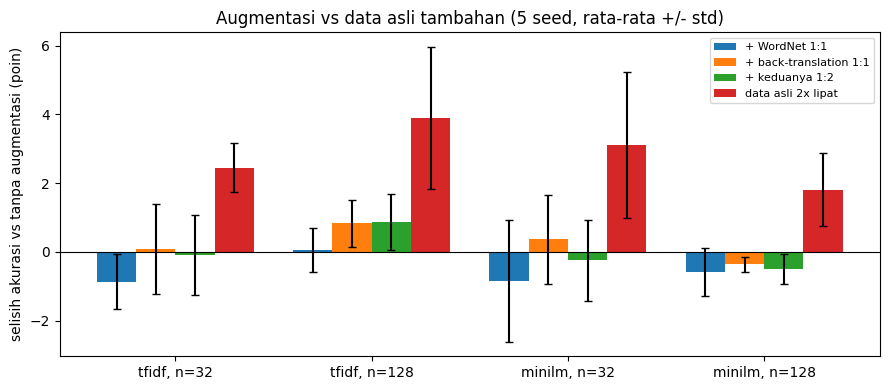

model yang masih dimuat: ['embedder', 'oracle']


In [29]:
PX = [s for _, s, _ in POOL]
PY = np.array([l for _, _, l in POOL])
random.seed(1)
P_SYN = [synonym_replacement_det(s, n=2) for s in PX]
tr = Translator()
P_BT = tr.translate_batch(tr.translate_batch(PX, "fr", num_beams=1), "en", src="fr", num_beams=1)
del tr
release("mt:en-fr", "mt:fr-en")

TRAIN_RECORDS = ([(g, s, l, "asli") for g, s, l in POOL]
                 + [(g, v, l, "wordnet") for (g, _, l), v in zip(POOL, P_SYN)]
                 + [(g, v, l, "bt_fr") for (g, _, l), v in zip(POOL, P_BT)])
same_as_eval = [r for r in TRAIN_RECORDS if norm(r[1]) in EVAL_NORM]
assert not same_as_eval, f"teks training identik dengan kalimat evaluasi: {same_as_eval[:3]}"
E_P, E_SYN, E_BT, E_VAL = embed(PX), embed(P_SYN), embed(P_BT), embed(EVAL_X)
nearest = (np.vstack([E_P, E_SYN, E_BT]) @ E_VAL.T).max(1)
print(f"POOL {len(POOL)} kalimat ({int(PY.sum())} positif) + {len(P_SYN)} varian WordNet + {len(P_BT)} varian back-translation")
print(f"teks training identik dengan kalimat evaluasi: 0 | cosine tertinggi ke kalimat evaluasi: median {np.median(nearest):.3f}, "
      f">= 0.95: {int((nearest >= 0.95).sum())} dari {len(nearest)}")
print(f"varian back-translation identik dengan sumbernya: {np.mean([norm(a) == norm(b) for a, b in zip(P_BT, PX)]):.1%}")

SRC = {"asli": (PX, E_P), "syn": (P_SYN, E_SYN), "bt": (P_BT, E_BT)}


def fit_eval(parts, feats):
    texts = [SRC[k][0][i] for k, idx in parts for i in idx]
    y = np.concatenate([PY[idx] for _, idx in parts])
    if feats == "tfidf":
        return np.mean(fit_tfidf(texts, y)(EVAL_X) == EVAL_Y)
    X = np.concatenate([SRC[k][1][idx] for k, idx in parts])
    return np.mean(LogisticRegression(C=1.0, max_iter=2000).fit(X, y).predict(E_VAL) == EVAL_Y)


CONDS = ["tanpa augmentasi", "+ WordNet 1:1", "+ back-translation 1:1", "+ keduanya 1:2", "data asli 2x lipat"]
pos_i, neg_i = np.where(PY == 1)[0], np.where(PY == 0)[0]
RES = collections.defaultdict(list)
for feats in ["tfidf", "minilm"]:
    for n in CFG["train_sizes"]:
        for seed in range(CFG["seeds"]):
            r = np.random.RandomState(seed)
            p, q = r.permutation(pos_i), r.permutation(neg_i)
            base, more = np.concatenate([p[:n // 2], q[:n // 2]]), np.concatenate([p[:n], q[:n]])
            plan = {"tanpa augmentasi": [("asli", base)],
                    "+ WordNet 1:1": [("asli", base), ("syn", base)],
                    "+ back-translation 1:1": [("asli", base), ("bt", base)],
                    "+ keduanya 1:2": [("asli", base), ("syn", base), ("bt", base)],
                    "data asli 2x lipat": [("asli", more)]}
            for c in CONDS:
                RES[(feats, n, c)].append(fit_eval(plan[c], feats))

groups = [(f, n) for f in ["tfidf", "minilm"] for n in CFG["train_sizes"]]
for f, n in groups:
    base = np.array(RES[(f, n, "tanpa augmentasi")])
    print(f"{f} | n={n} kalimat asli | tanpa augmentasi {base.mean():.3f} +/- {base.std():.3f} ({CFG['seeds']} seed, eval {len(EVAL_X)})")
    for c in CONDS[1:]:
        d = np.array(RES[(f, n, c)]) - base
        print(f"   {c:<24} selisih berpasangan {d.mean() * 100:+.1f} +/- {d.std() * 100:.1f} poin | naik di {int((d > 0).sum())}/{len(d)} seed")

fig, ax = plt.subplots(figsize=(9, 4))
for j, c in enumerate(CONDS[1:]):
    d = [np.array(RES[(f, n, c)]) - np.array(RES[(f, n, "tanpa augmentasi")]) for f, n in groups]
    ax.bar(np.arange(len(groups)) + (j - 1.5) * 0.2, [x.mean() * 100 for x in d], 0.2,
           yerr=[x.std() * 100 for x in d], capsize=3, label=c)
ax.axhline(0, c="k", lw=0.8)
ax.set_xticks(range(len(groups)))
ax.set_xticklabels([f"{f}, n={n}" for f, n in groups])
ax.set_ylabel("selisih akurasi vs tanpa augmentasi (poin)")
ax.set_title(f"Augmentasi vs data asli tambahan ({CFG['seeds']} seed, rata-rata +/- std)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("model yang masih dimuat:", sorted(_LOADED))

Baris-baris pertama adalah pemeriksaan kebocoran untuk eksperimen ini: tidak ada teks training yang identik dengan kalimat
evaluasi, dan cosine tertinggi setiap teks training ke kalimat evaluasi mana pun dilaporkan, supaya hampir-duplikat terlihat bila
ada.

Untuk membaca hasilnya, perhatikan satuannya: selisih dalam **poin persentase** akurasi, rata-rata ± simpangan baku atas 5 seed,
pada 872 kalimat validation (satu kalimat ≈ 0,11 poin). Di run historis dengan pool yang sama, augmentasi menggeser akurasi antara
−0,9 dan +0,9 poin, dengan arah yang tidak konsisten: back-translation sedikit menolong TF-IDF di n=128 (+0,8) tetapi sedikit
merugikan MiniLM di n=128; WordNet tidak pernah positif. Batang **data asli 2× lipat** — dengan jumlah baris yang sama dengan kondisi
1:1 — memberi +1,8 sampai +3,9 poin di keempat rezim. Dalam rezim yang paling dijagokan untuk augmentasi, satu kalimat berlabel baru
bernilai jauh lebih banyak daripada satu kalimat augmentasi.

Ini konsisten dengan temuan sebelumnya: augmentasi yang setia (back-translation) hanya menambah sedikit informasi baru, sedangkan
augmentasi yang bervariasi (WordNet) membawa teks rusak dan sebagian label yang terbalik. MiniLM sudah tahu bahwa *film* dan
*movie* bersinonim, jadi mengajarkannya lewat augmentasi tidak menambah apa pun; TF-IDF yang buta sinonim sesekali mendapat
sedikit manfaat. Dengan 5 seed, selisih di bawah satu simpangan baku belum bisa dibedakan dari variasi pemilihan sampel.

Batas pengukurannya jelas: classifier linear di atas fitur beku (bukan fine-tuning LLM), dua metode augmentasi, satu tugas, satu
bahasa. Augmentasi yang menargetkan kelemahan spesifik — ketahanan terhadap typo, kelas minoritas, bahasa lain — bisa bernilai
lebih. Tetapi sebagai titik awal, angka ini membalik urutan yang disarankan buku: ukur dulu apakah augmentasi menolong di tugas
Anda, dengan pembanding data asli tambahan, alih-alih mulai dari 1:1 lalu "menyesuaikan".

## Ringkasan

Tiga belas listing, satu pertanyaan — apakah label selamat setelah teks diubah? — dan jawabannya hampir selalu "tidak terjamin".
Angka dalam kurung berasal dari run historis notebook asal; run Anda akan memberi angka sendiri.

- **Synonym replacement.** `random.seed` saja tidak membuat hasilnya bisa diulang; dua `sorted()` memperbaikinya. Filter
  `isalnum()` mengarahkan banyak penggantian ke stopword (30,0%: `it` → `information technology`) dan mengunci kata yang menempel
  tanda baca. Flip-nya rendah karena yang rusak tata bahasanya, bukan sentimennya.
- **Back-translation.** Fasih tetapi bergeser: *acting* menjadi *act*, *adroitly* menjadi *sloppyly*. Kesalahan penerjemah adalah
  sumber variasinya sekaligus sumber risikonya.
- **Parafrase T5.** T5 vanilla tidak mengenal `paraphrase:`; checkpoint parafrase mengenalnya. `top_k`/`top_p` di listing buku
  tidak berbuat apa-apa tanpa `do_sample`; sampling murni menambah keragaman dengan mengorbankan kesetiaan.
- **Temperature.** T = 1 adalah distribusi asli model; T < 1 menajamkan; meratakan butuh T > 1.
- **Data buatan LLM.** Satu kata di prompt mengubah porsi sampel layak pakai (7/8 vs 2/8). Penolakan, sampel terpotong, label
  meleset, dan entitas karangan harus disaring. Istilah yang tepat: synthetic data generation atau distilasi.
- **Multibahasa.** Setiap pivot membawa kesalahan yang berbeda; listing multilingual T5 menghasilkan kalimat karangan, bahasa yang
  salah, atau `'<extra_id_0>'`. Juri berbahasa Inggris tidak bisa memeriksa label teks berbahasa lain.
- **Pelestarian makna.** Ambang cosine 0,8 meloloskan hampir semua negasi (97,1% pasangan negasi yang membuat juri berubah pikiran
  tetap lolos) dan membuang banyak parafrase yang setia.
- **Kontekstual.** Indeks kata dipakai sebagai indeks token, sehingga hampir tidak ada posisi yang membaca kata yang dimaksud.
  Setelah diperbaiki, mengganti kata penentu label membalik seperempat sampai sepertiga kalimat, dengan cosine tetap tinggi.
- **Kualitas dan evaluasi.** Ambang perplexity 100 menolak sebagian besar kalimat asli SST-2; kriteria relatif terhadap sumbernya
  jauh lebih masuk akal. Satu teks satu-token membuat perplexity listing menjadi NaN. Metrik keragaman memberi skor tertinggi pada
  typo acak.
- **Kebocoran dan dampak.** Augmentasi sebelum split membuat skor test internal naik tanpa model menjadi lebih baik. Dengan split
  yang benar, augmentasi 1:1 menggeser akurasi −0,9 sampai +0,9 poin; data asli 2× lipat +1,8 sampai +3,9 poin.

Resep yang bertahan dari semua pengukuran ini: perlakukan augmentasi sebagai hipotesis yang diuji per tugas, bukan langkah default.
Bagi data per kalimat asli sebelum membuat varian. Buat augmentasi deterministik. Saring dengan pemeriksa label — dan baca contohnya
— bukan hanya dengan cosine. Nilai perplexity relatif terhadap kalimat sumbernya. Dan bandingkan dengan pembanding data asli tambahan
sebelum memasukkan augmentasi ke pipeline training.